In [122]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

## 01- Dataset Acuisition and Initial Inspection

In [123]:
# import dataset

base_features = [
"radius", "texture", "perimeter", "area", "smoothness",
"compactness", "concavity", "concave_points",
"symmetry", "fractal_dimension"
]
columns = (
["id", "diagnosis"]
+ [f"{x}_mean" for x in base_features]
+ [f"{x}_se" for x in base_features]
+ [f"{x}_worst" for x in base_features]
)

df=pd.read_csv("/content/wdbc.data",header=None,names=columns)

In [124]:
df

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
564,926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
565,926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
566,926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820
567,927241,M,20.60,29.33,140.10,1265.0,0.11780,0.27700,0.35140,0.15200,...,25.740,39.42,184.60,1821.0,0.16500,0.86810,0.9387,0.2650,0.4087,0.12400


In [125]:
print(f"The number of observations in dataset is {df.shape[0]} and columns is {df.shape[1]}")
print(f"Datatype is: \n{df.dtypes}")

The number of observations in dataset is 569 and columns is 32
Datatype is: 
id                           int64
diagnosis                   object
radius_mean                float64
texture_mean               float64
perimeter_mean             float64
area_mean                  float64
smoothness_mean            float64
compactness_mean           float64
concavity_mean             float64
concave_points_mean        float64
symmetry_mean              float64
fractal_dimension_mean     float64
radius_se                  float64
texture_se                 float64
perimeter_se               float64
area_se                    float64
smoothness_se              float64
compactness_se             float64
concavity_se               float64
concave_points_se          float64
symmetry_se                float64
fractal_dimension_se       float64
radius_worst               float64
texture_worst              float64
perimeter_worst            float64
area_worst                 float64
smoothness_wo

In [126]:
print(f"First 5 records are: \n{df.head()}")





First 5 records are: 
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402         M        20.29         14.34          135.10     1297.0   

   smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
0          0.11840           0.27760          0.3001              0.14710   
1          0.08474           0.07864          0.0869              0.07017   
2          0.10960           0.15990          0.1974              0.12790   
3          0.14250           0.28390          0.2414              0.10520   
4          0.10030           0.13280          0.1980              0.10430   

   ...  radius_worst  texture_worst  per

In [127]:
print(f"Last 5 records are: \n{df.tail()}")

Last 5 records are: 
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
564  926424         M        21.56         22.39          142.00     1479.0   
565  926682         M        20.13         28.25          131.20     1261.0   
566  926954         M        16.60         28.08          108.30      858.1   
567  927241         M        20.60         29.33          140.10     1265.0   
568   92751         B         7.76         24.54           47.92      181.0   

     smoothness_mean  compactness_mean  concavity_mean  concave_points_mean  \
564          0.11100           0.11590         0.24390              0.13890   
565          0.09780           0.10340         0.14400              0.09791   
566          0.08455           0.10230         0.09251              0.05302   
567          0.11780           0.27700         0.35140              0.15200   
568          0.05263           0.04362         0.00000              0.00000   

     ...  radius_worst  textu

In [128]:
#Number of unique values
unique_counts=df.nunique()
print(f"Number of Unique values: \n{unique_counts}")

Number of Unique values: 
id                         569
diagnosis                    2
radius_mean                456
texture_mean               479
perimeter_mean             522
area_mean                  539
smoothness_mean            474
compactness_mean           537
concavity_mean             537
concave_points_mean        542
symmetry_mean              432
fractal_dimension_mean     499
radius_se                  540
texture_se                 519
perimeter_se               533
area_se                    528
smoothness_se              547
compactness_se             541
concavity_se               533
concave_points_se          507
symmetry_se                498
fractal_dimension_se       545
radius_worst               457
texture_worst              511
perimeter_worst            514
area_worst                 544
smoothness_worst           411
compactness_worst          529
concavity_worst            539
concave_points_worst       492
symmetry_worst             500
fractal_dimen

In [129]:
#Number of duplicate rows

duplicate_counts=df.duplicated().sum()
print(f"Number of Duplicate rows is {duplicate_counts}")

Number of Duplicate rows is 0


In [130]:
#Number of missing value  in every column

missing_values=df.isnull().sum()

print(f"Number of missing value is \n{missing_values}")

Number of missing value is 
id                         0
diagnosis                  0
radius_mean                0
texture_mean               0
perimeter_mean             0
area_mean                  0
smoothness_mean            0
compactness_mean           0
concavity_mean             0
concave_points_mean        0
symmetry_mean              0
fractal_dimension_mean     0
radius_se                  0
texture_se                 0
perimeter_se               0
area_se                    0
smoothness_se              0
compactness_se             0
concavity_se               0
concave_points_se          0
symmetry_se                0
fractal_dimension_se       0
radius_worst               0
texture_worst              0
perimeter_worst            0
area_worst                 0
smoothness_worst           0
compactness_worst          0
concavity_worst            0
concave_points_worst       0
symmetry_worst             0
fractal_dimension_worst    0
dtype: int64


In [131]:
#Remove Id and target Variable
X=df.drop(columns=["id","diagnosis"])
y=df["diagnosis"].map({})

In [132]:
#varify Predictive feature matrix
print("PREDICTIVE FEATURE MATRIX: ")
print("=" *25)

print(f"Shape of X: {X.shape}")

print(f"Number or predictive feature: {X.shape[1]}")
print(f"Datatype of predictive feature: \n{X.dtypes.value_counts()}")

print("Are all predictive features numberical?: ", X.select_dtypes(include=np.number).shape[1]==30)

PREDICTIVE FEATURE MATRIX: 
Shape of X: (569, 30)
Number or predictive feature: 30
Datatype of predictive feature: 
float64    30
Name: count, dtype: int64
Are all predictive features numberical?:  True


In [133]:
#Dignosis Distribution

print("DIGNOSIS DISTRIBUTION:")
print("=" *22)

diagnosis_counts=df["diagnosis"].value_counts()
diagnosis_percent=df["diagnosis"].value_counts(normalize=True)*(100)


diagnosis_summary=pd.DataFrame({
    "Count":diagnosis_counts,
    "Percentage":diagnosis_percent.round(2)
})

print(diagnosis_summary)

DIGNOSIS DISTRIBUTION:
           Count  Percentage
diagnosis                   
B            357       62.74
M            212       37.26


In [134]:
#Feature Groups (BAR GRAPH)

print("FEATURE GROUPS:")
print("=" *20)

print("Mean Feature:")
print([f"{x}_mean"  for x in base_features])

print("\nStandard Error Feature:")
print([f"{x}_se" for x in base_features])

print("\nWorst Feature:")
print([f"{x}_worst" for x in base_features])

FEATURE GROUPS:
Mean Feature:
['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean']

Standard Error Feature:
['radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se']

Worst Feature:
['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst']


##Why ID should not be used?
The id column identifies as observation, it dose not represent the measured characteristic  of the cell nucleus.
Incluiding ID as ML featurer could allow the model to learn meaningless numberical patterns from the identifier. Therefore, the assignment explicitly instructed to remove it befor classification.

## 02- Exploratory Data Analysis and Feature Redundancy

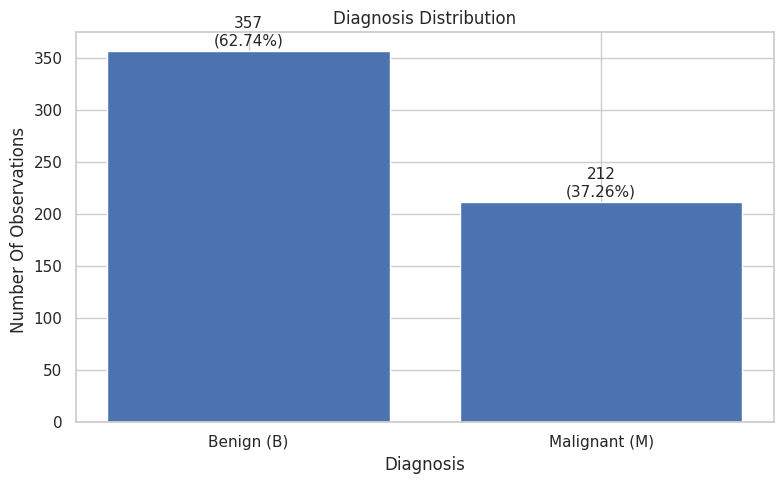

In [135]:
#Diagnosis Distribution

diagnosis_counts=df["diagnosis"].value_counts().reindex(["B","M"])
diagnosis_percentage=(
    df["diagnosis"].value_counts(normalize=True).reindex(["B","M"])*100
)

labels=["Benign (B)", "Malignant (M)"]

plt.figure(figsize=(8,5))

bars=plt.bar(labels,diagnosis_counts.values)
plt.title("Diagnosis Distribution")
plt.xlabel("Diagnosis")
plt.ylabel("Number Of Observations ")



for bar , count , percent in zip(
    bars,
    diagnosis_counts.values,
    diagnosis_percent.values
):

  plt.text(
      bar.get_x()+bar.get_width()/2,
      bar.get_height() +5,
      f"{count}\n({percent:.2f}%)",
      ha="center",
      fontsize=11
  )
plt.tight_layout()
plt.show()









##Interpretation:

The dataset represent more Benign observation then malignant Observation.The Bengig observation is approx 62.74% and Malignant observation is approx 37.26% . Here clearly seen that dataset is not balanced.


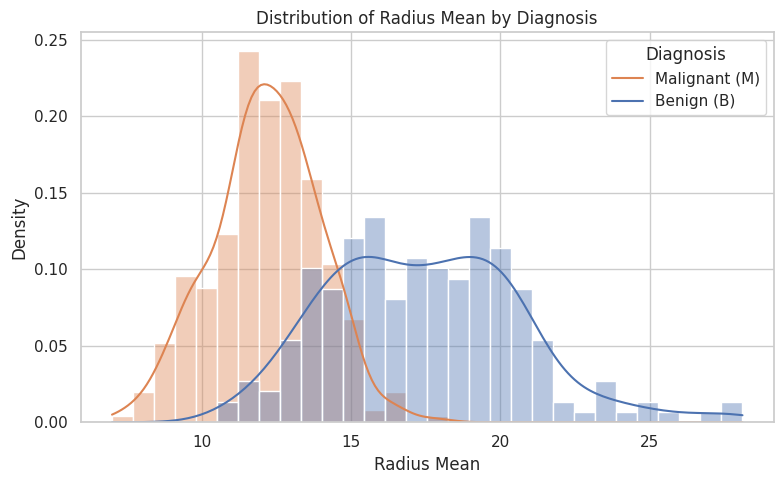

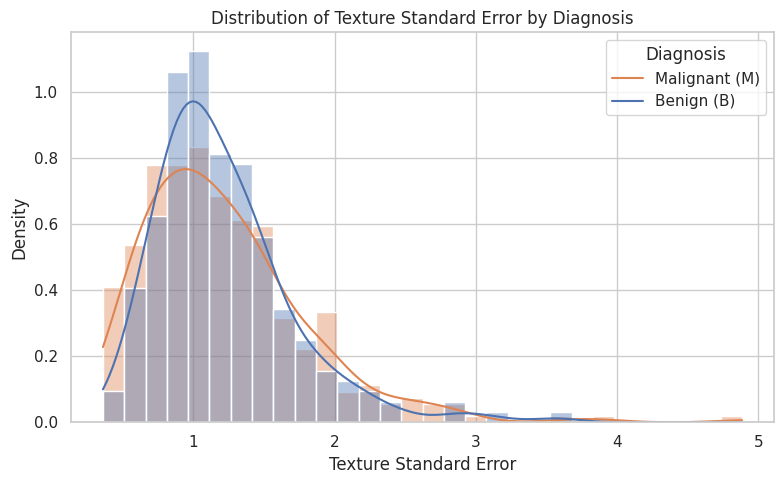

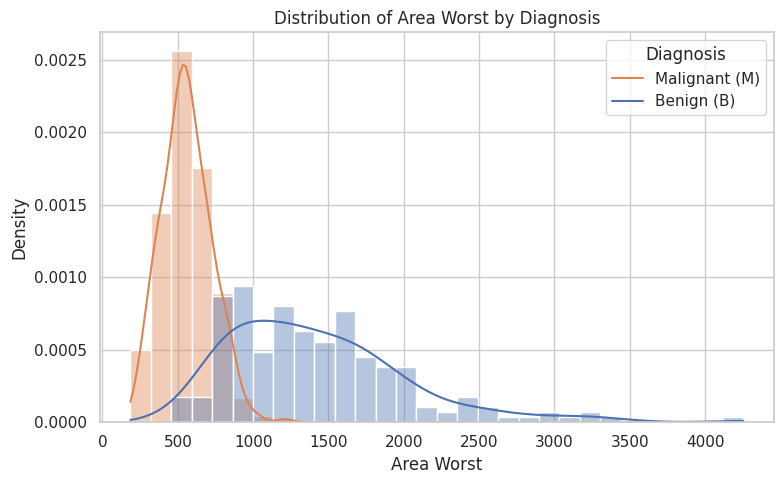

In [136]:
# HISTOGRAM/KDE Plots

selected_features=[
    "radius_mean",
    "texture_se",
    "area_worst"
]

feature_titles={
    "radius_mean":"Radius Mean",
    "texture_se":"Texture Standard Error",
    "area_worst":"Area Worst"
}

for feature in selected_features:
  plt.figure(figsize=(8,5))

  sns.histplot(
      data=df,
      x=feature,
      hue="diagnosis",
      kde=True,
      bins=30,
      stat="density",
      common_norm=False,
      alpha=0.4
  )


  plt.title(f"Distribution of {feature_titles[feature]} by Diagnosis")
  plt.xlabel(feature_titles[feature])
  plt.ylabel("Density")
  plt.legend(title="Diagnosis",labels=["Malignant (M)","Benign (B)"])

  plt.tight_layout()
  plt.show()

##Interpretation-

The distributions of the selected features differ between benign and malignant observations. In particular, measurements related to cell size and geometry can show substantial distributional differences between the two classes. However, overlap between the distributions is also present, indicating that individual features may not completely separate the two diagnosis categories.

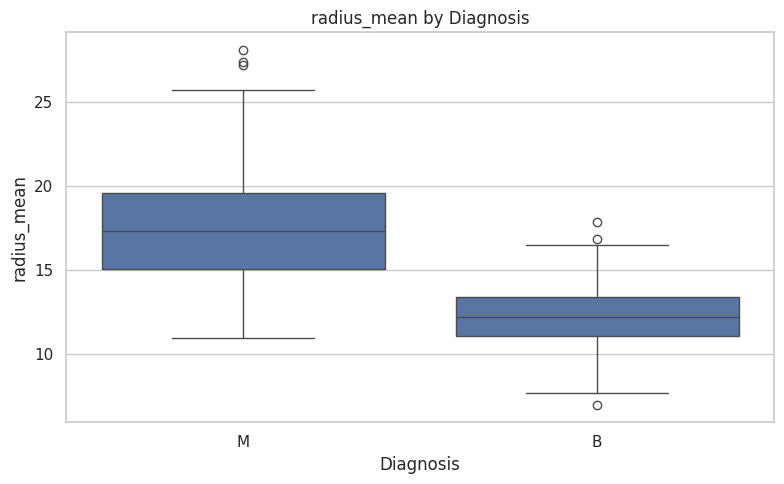

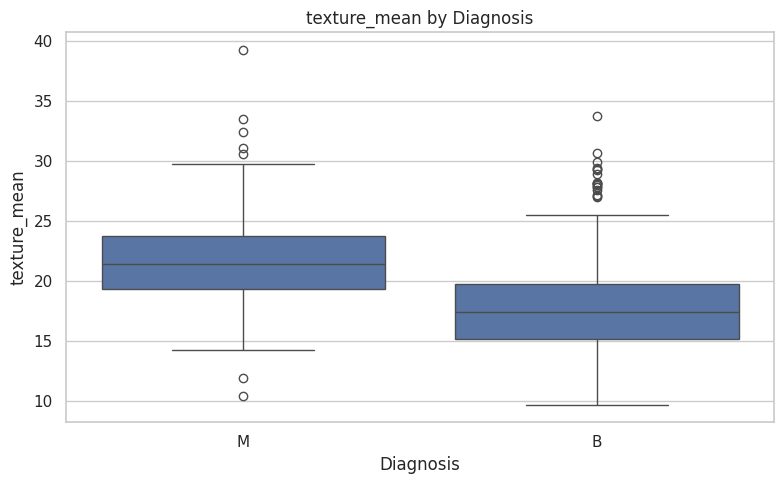

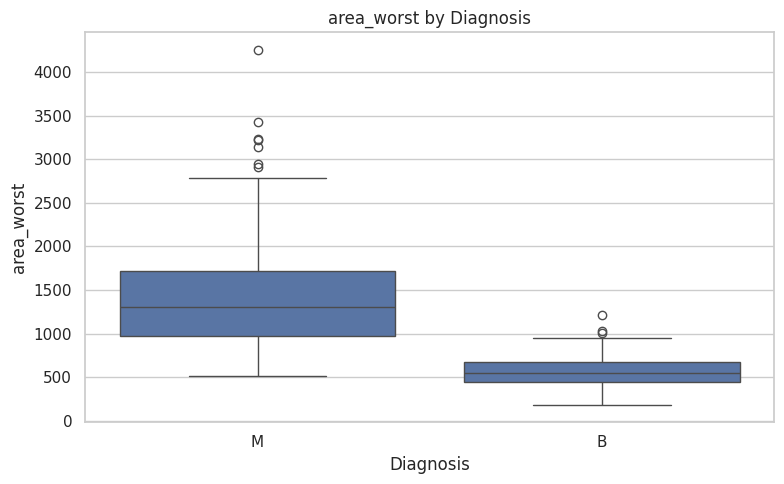

In [137]:
#Boxplot
selected_feature=[
    "radius_mean",
    "texture_mean",
    "area_worst"
]

for feature in selected_feature:
  plt.figure(figsize=(8,5))

  sns.boxplot(
      data=df,
      x="diagnosis",
      y=feature
  )

  plt.title(f"{feature} by Diagnosis")
  plt.xlabel("Diagnosis")
  plt.ylabel(feature)

  plt.tight_layout()
  plt.show()


##Interpretation

The box plots show differences in the central tendency and spread of the selected features between benign and malignant samples. Several features exhibit different median values and distributions between the two diagnosis groups. Some outliers are also visible, showing that individual observations can differ substantially from the majority of samples.



Correlation matrix shape: (30, 30)


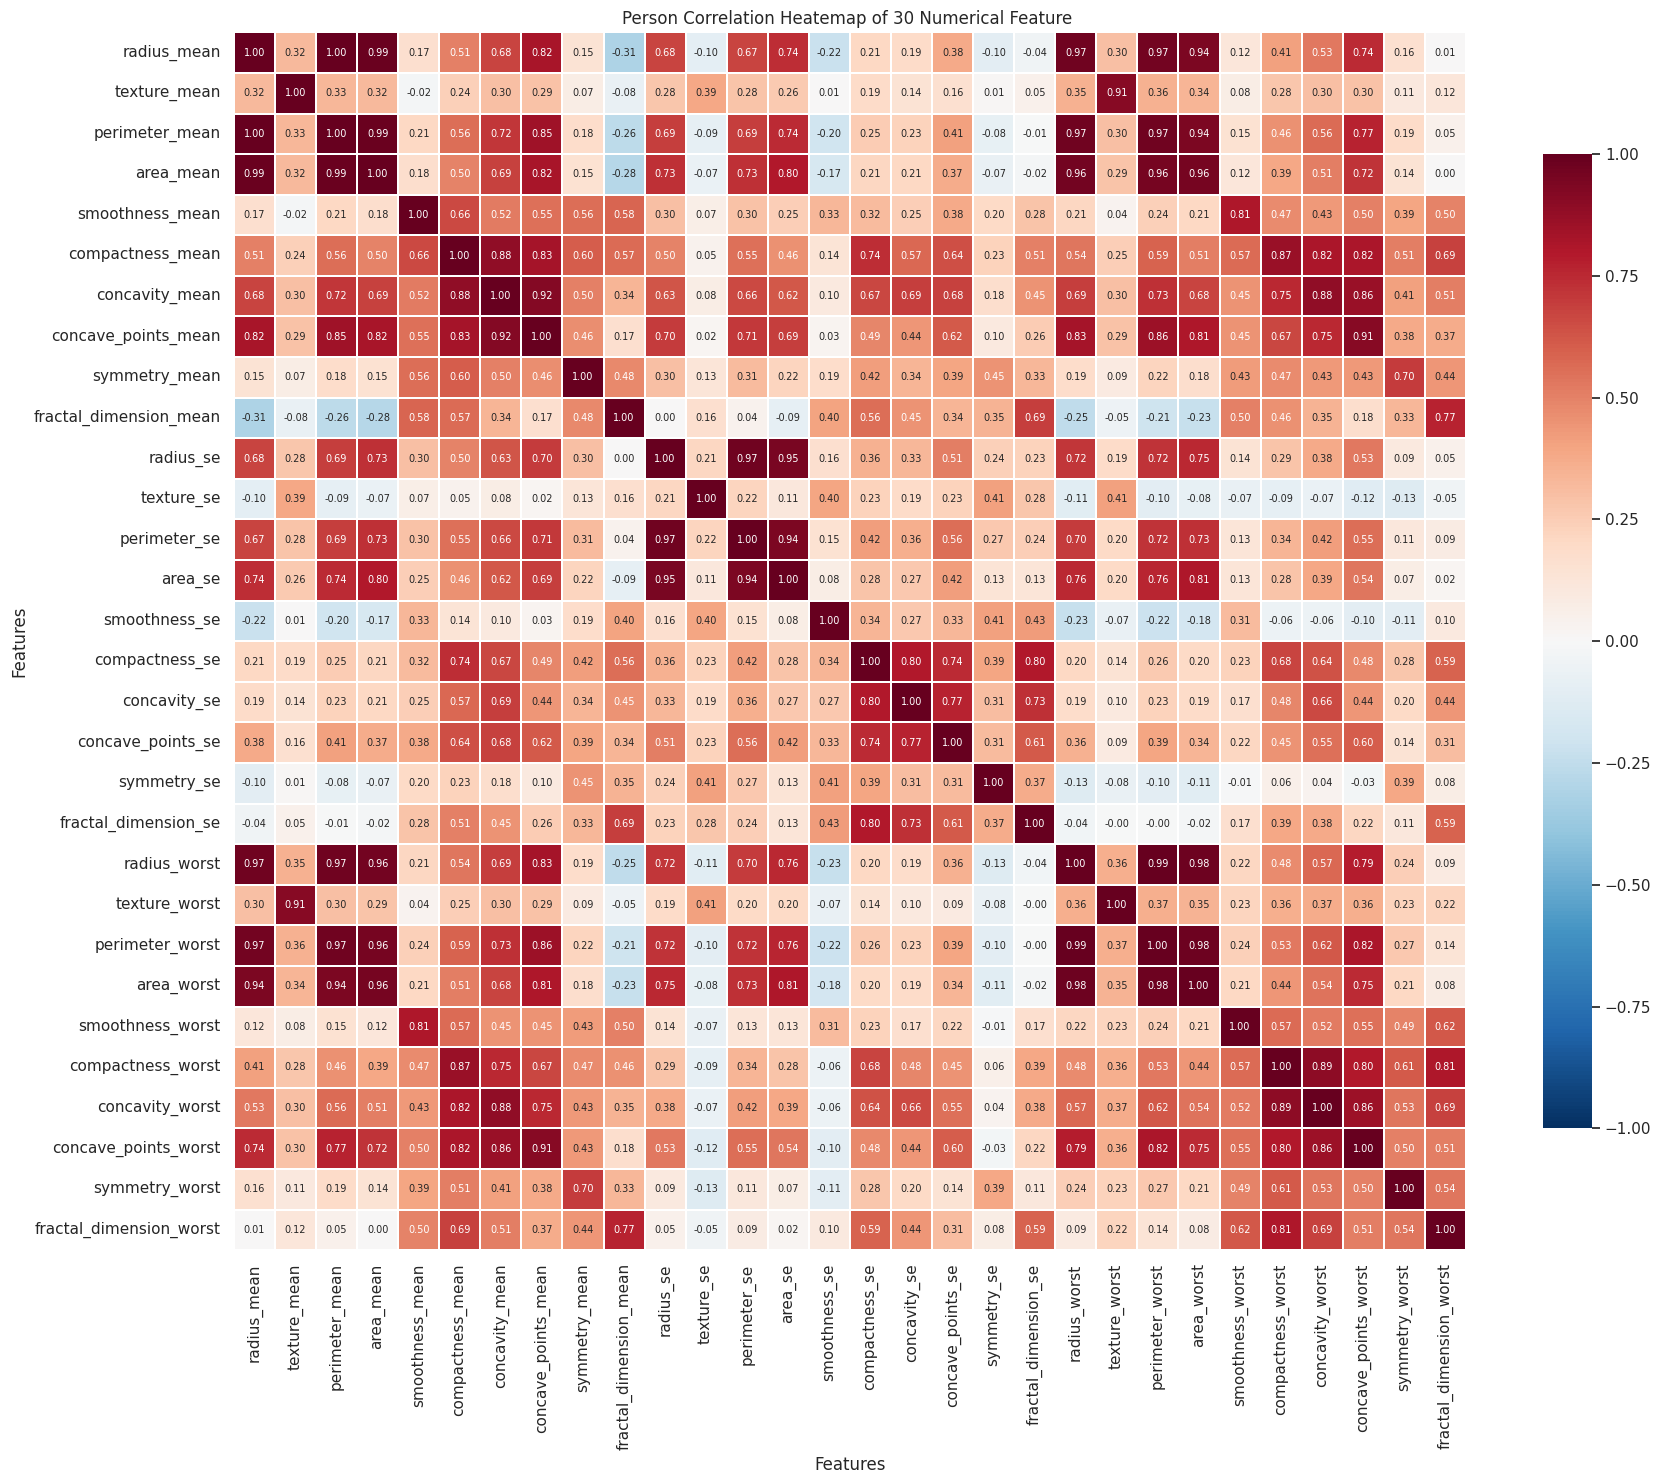

In [138]:
#Corelation heatmap

correlation_matrix= X.corr(method="pearson")

print("Correlation matrix shape:", correlation_matrix.shape)


plt.figure(figsize=(18,15))


sns.heatmap(
    correlation_matrix,


    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.3,
    annot_kws={"size": 7},
    cbar_kws={"shrink": 0.8}
)

plt.title("Person Correlation Heatemap of 30 Numerical Feature ")
plt.xlabel("Features")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

##Interpretation-

The correlation heatmap shows several groups of strongly correlated features. In particular, measurements related to radius, perimeter, and area show strong relationships because they describe related geometric properties of cell nuclei. This indicates that the 30-dimensional feature representation contains redundant information

In [139]:



# Get upper triangle of correlation matrix
upper_triangle = correlation_matrix.where(
    np.triu(np.ones(correlation_matrix.shape), k=1).astype(bool)
)

# Convert correlations into a long-format table
high_corr_pairs = (
    upper_triangle
    .stack()
    .reset_index()
)

high_corr_pairs.columns = [
    "Feature 1",
    "Feature 2",
    "Correlation"
]

# Keep correlations with absolute value >= 0.90
high_corr_pairs = high_corr_pairs[
    high_corr_pairs["Correlation"].abs() >= 0.90
]

# Sort by absolute correlation
high_corr_pairs["Absolute Correlation"] = (
    high_corr_pairs["Correlation"].abs()
)

high_corr_pairs = high_corr_pairs.sort_values(
    by="Absolute Correlation",
    ascending=False
)

print("Highly Correlated Feature Pairs (|r| >= 0.90)")
print("=" * 70)

display(high_corr_pairs)

Highly Correlated Feature Pairs (|r| >= 0.90)


,Feature 1,Feature 2,Correlation,Absolute Correlation
1,radius_mean,perimeter_mean,0.997855,0.997855
391,radius_worst,perimeter_worst,0.993708,0.993708
2,radius_mean,area_mean,0.987357,0.987357
57,perimeter_mean,area_mean,0.986507,0.986507
392,radius_worst,area_worst,0.984015,0.984015
407,perimeter_worst,area_worst,0.977578,0.977578
246,radius_se,perimeter_se,0.972794,0.972794
76,perimeter_mean,perimeter_worst,0.970387,0.970387
19,radius_mean,radius_worst,0.969539,0.969539
74,perimeter_mean,radius_worst,0.969476,0.969476


Selected features:
Feature 1: radius_mean
Feature 2: perimeter_mean
Correlation: 0.9978552814938109


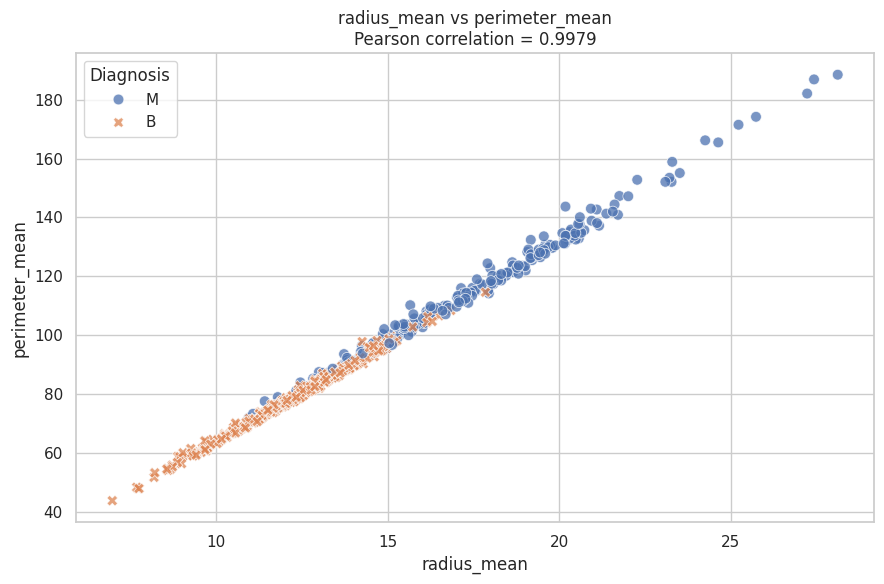

In [140]:

#  Multivariate Scatter Plot

# Select strongest correlated pair
strongest_pair = high_corr_pairs.iloc[0]

feature_1 = strongest_pair["Feature 1"]
feature_2 = strongest_pair["Feature 2"]
correlation_value = strongest_pair["Correlation"]

print("Selected features:")
print("Feature 1:", feature_1)
print("Feature 2:", feature_2)
print("Correlation:", correlation_value)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    data=df,
    x=feature_1,
    y=feature_2,
    hue="diagnosis",
    style="diagnosis",
    alpha=0.75,
    s=60
)

plt.title(
    f"{feature_1} vs {feature_2}\n"
    f"Pearson correlation = {correlation_value:.4f}"
)

plt.xlabel(feature_1)
plt.ylabel(feature_2)
plt.legend(title="Diagnosis")

plt.tight_layout()
plt.show()

##Interpretation

The scatter plot demonstrates a strong approximately linear relationship between the selected feature pair. The observations form a structured pattern rather than being randomly distributed, which is consistent with the high Pearson correlation. The two diagnosis groups may show partial separation, but considerable overlap can remain. The strong relationship between the features indicates that both variables contain overlapping information.

In [141]:

#  Redundancy Summary


num_high_corr = len(high_corr_pairs)

print("\nREDUNDANCY SUMMARY")
print("=" * 50)

print("Total numerical features:", X.shape[1])
print("Number of feature pairs with |r| >= 0.90:", num_high_corr)

if num_high_corr > 0:
    print("\nConclusion:")
    print("The dataset contains strongly correlated features.")
    print("Therefore, the 30-dimensional representation contains")
    print("redundant information.")
else:
    print("\nNo feature pairs satisfy |r| >= 0.90.")


REDUNDANCY SUMMARY
Total numerical features: 30
Number of feature pairs with |r| >= 0.90: 21

Conclusion:
The dataset contains strongly correlated features.
Therefore, the 30-dimensional representation contains
redundant information.


In [142]:
# Top 5 highly correlated feature pairs

top_5_pairs = high_corr_pairs.head(5).copy()

top_5_pairs = top_5_pairs[
    ["Feature 1", "Feature 2", "Correlation"]
]

print("TOP 5 HIGHLY CORRELATED FEATURE PAIRS")
print("=" * 60)

display(top_5_pairs)

TOP 5 HIGHLY CORRELATED FEATURE PAIRS


,Feature 1,Feature 2,Correlation
1,radius_mean,perimeter_mean,0.997855
391,radius_worst,perimeter_worst,0.993708
2,radius_mean,area_mean,0.987357
57,perimeter_mean,area_mean,0.986507
392,radius_worst,area_worst,0.984015


##Conclusion

Exploratory data analysis shows that the dataset contains differences in the distributions of several numerical features between benign and malignant observations. The correlation heatmap reveals strong relationships among several of the 30 numerical features, particularly among measurements describing related geometric properties such as radius, perimeter, and area. Multiple feature pairs satisfy the required \(|r| \geq 0.90\) threshold, demonstrating substantial feature redundancy. Therefore, the original 30-dimensional representation contains overlapping information. This redundancy motivates the investigation of dimensionality-reduction techniques such as PCA and SVD in the subsequent tasks.

## 03-Standardisation and Baseline Classification

In [143]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [144]:

# Prepare Features and Target


X = df.drop(columns=["id", "diagnosis"])

# M = 1 (Malignant)
# B = 0 (Benign)
y = df["diagnosis"].map({
    "M": 1,
    "B": 0
})

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (569, 30)
y shape: (569,)


In [145]:

# Train-Test Split


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training set shape:", X_train.shape)
print("Testing set shape :", X_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTesting target distribution:")
print(y_test.value_counts())

Training set shape: (455, 30)
Testing set shape : (114, 30)

Training target distribution:
diagnosis
0    285
1    170
Name: count, dtype: int64

Testing target distribution:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [146]:

# Standardisation


scaler = StandardScaler()

# IMPORTANT:
# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform test data using the SAME training parameters
X_test_scaled = scaler.transform(X_test)

print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape :", X_test_scaled.shape)

Scaled training shape: (455, 30)
Scaled testing shape : (114, 30)


In [147]:

# Verify Standardisation


X_train_scaled_df = pd.DataFrame(
    X_train_scaled,
    columns=X_train.columns
)

print("Mean of first 5 scaled training features:")
print(X_train_scaled_df.iloc[:, :5].mean())

print("\nStandard deviation of first 5 scaled training features:")
print(X_train_scaled_df.iloc[:, :5].std())

Mean of first 5 scaled training features:
radius_mean       -1.737316e-16
texture_mean       3.904081e-16
perimeter_mean     4.704418e-16
area_mean         -1.171224e-16
smoothness_mean    7.242070e-16
dtype: float64

Standard deviation of first 5 scaled training features:
radius_mean        1.001101
texture_mean       1.001101
perimeter_mean     1.001101
area_mean          1.001101
smoothness_mean    1.001101
dtype: float64


In [148]:
print("\nMaximum absolute training mean:")
print(abs(X_train_scaled_df.mean()).max())

print("\nTraining standard deviations:")
print(X_train_scaled_df.std().head())


Maximum absolute training mean:
7.242070191401021e-16

Training standard deviations:
radius_mean        1.001101
texture_mean       1.001101
perimeter_mean     1.001101
area_mean          1.001101
smoothness_mean    1.001101
dtype: float64


##Why standardisation is important before PCA:
The 30 features have different numerical scales and units. For example, area measurements have much larger numerical values than features such as smoothness. Without standardisation, features with larger numerical scales could have a greater influence on the covariance matrix and consequently on PCA directions. Standardisation places the features on a comparable scale by giving them approximately zero mean and unit standard deviation.

In [149]:

# Logistic Regression


logistic_model = LogisticRegression(
    max_iter=10000,
    random_state=42
)

logistic_model.fit(
    X_train_scaled,
    y_train
)

# Predictions
y_pred_lr = logistic_model.predict(X_test_scaled)

# Probability of malignant class
y_prob_lr = logistic_model.predict_proba(X_test_scaled)[:, 1]

In [150]:

# Logistic Regression Evaluation


lr_accuracy = accuracy_score(y_test, y_pred_lr)

lr_precision = precision_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

lr_recall = recall_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

lr_f1 = f1_score(
    y_test,
    y_pred_lr,
    zero_division=0
)

lr_roc_auc = roc_auc_score(
    y_test,
    y_prob_lr
)

print("LOGISTIC REGRESSION")
print("=" * 50)

print(f"Accuracy : {lr_accuracy:.4f}")
print(f"Precision: {lr_precision:.4f}")
print(f"Recall   : {lr_recall:.4f}")
print(f"F1 Score : {lr_f1:.4f}")
print(f"ROC-AUC  : {lr_roc_auc:.4f}")

LOGISTIC REGRESSION
Accuracy : 0.9649
Precision: 0.9750
Recall   : 0.9286
F1 Score : 0.9512
ROC-AUC  : 0.9960


In [151]:

# k-Nearest Neighbours (k = 5)


knn_model = KNeighborsClassifier(
    n_neighbors=5
)

knn_model.fit(
    X_train_scaled,
    y_train
)

# Predictions
y_pred_knn = knn_model.predict(X_test_scaled)

# Probability of malignant class
y_prob_knn = knn_model.predict_proba(X_test_scaled)[:, 1]

In [152]:

# k-NN Evaluation


knn_accuracy = accuracy_score(
    y_test,
    y_pred_knn
)

knn_precision = precision_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

knn_recall = recall_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

knn_f1 = f1_score(
    y_test,
    y_pred_knn,
    zero_division=0
)

knn_roc_auc = roc_auc_score(
    y_test,
    y_prob_knn
)

print("k-NN (k=5)")
print("=" * 50)

print(f"Accuracy : {knn_accuracy:.4f}")
print(f"Precision: {knn_precision:.4f}")
print(f"Recall   : {knn_recall:.4f}")
print(f"F1 Score : {knn_f1:.4f}")
print(f"ROC-AUC  : {knn_roc_auc:.4f}")

k-NN (k=5)
Accuracy : 0.9561
Precision: 0.9744
Recall   : 0.9048
F1 Score : 0.9383
ROC-AUC  : 0.9823


In [153]:

# Baseline Model Comparison


baseline_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "KNN (k=5)"
    ],

    "Accuracy": [
        lr_accuracy,
        knn_accuracy
    ],

    "Precision": [
        lr_precision,
        knn_precision
    ],

    "Recall": [
        lr_recall,
        knn_recall
    ],

    "F1": [
        lr_f1,
        knn_f1
    ],

    "ROC-AUC": [
        lr_roc_auc,
        knn_roc_auc
    ]
})

baseline_results = baseline_results.round(4)

display(baseline_results)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.9649,0.9750,0.9286,0.9512,0.9960
1,KNN (k=5),0.9561,0.9744,0.9048,0.9383,0.9823


##  04-bold text Covariance Matrix, Eigenvalues, and Eigenvectors

In [154]:


# COVARIANCE MATRIX, EIGENVALUES, EIGENVECTORS


# X_train_scaled was created in Task 3
Z = X_train_scaled

print("Shape of standardized training matrix Z:")
print(Z.shape)

# Number of training samples
n = Z.shape[0]



Shape of standardized training matrix Z:
(455, 30)


In [155]:

#  Compute covariance matrix


C = (Z.T @ Z) / (n - 1)

print("\nCovariance Matrix Shape:")
print(C.shape)

print("\nFirst 5 x 5 part of Covariance Matrix:")
print(C[:5, :5])


Covariance Matrix Shape:
(30, 30)

First 5 x 5 part of Covariance Matrix:
[[ 1.00220264  0.32707726  1.00001253  0.98891367  0.18922075]
 [ 0.32707726  1.00220264  0.33253119  0.3195129  -0.01177489]
 [ 1.00001253  0.33253119  1.00220264  0.98813207  0.22633794]
 [ 0.98891367  0.3195129   0.98813207  1.00220264  0.200474  ]
 [ 0.18922075 -0.01177489  0.22633794  0.200474    1.00220264]]


In [156]:
# : Check whether covariance matrix is symmetric


symmetry_error = np.linalg.norm(C - C.T)

print("\nSymmetry Error ||C - C.T||:")
print(symmetry_error)

if np.isclose(symmetry_error, 0):
    print("Covariance matrix is symmetric.")
else:
    print("Covariance matrix is NOT symmetric.")

#  Compute eigenvalues and eigenvectors


eigenvalues, eigenvectors = np.linalg.eigh(C)


Symmetry Error ||C - C.T||:
0.0
Covariance matrix is symmetric.


In [157]:
#  Sort eigenvalues in descending order


idx = np.argsort(eigenvalues)[::-1]

eigenvalues = eigenvalues[idx]
eigenvectors = eigenvectors[:, idx]


In [158]:
# STEP 5: Display eigenvalues


print("\nEigenvalues in descending order:")
for i, value in enumerate(eigenvalues, start=1):
    print(f"λ{i} = {value:.6f}")



Eigenvalues in descending order:
λ1 = 13.407524
λ2 = 5.575831
λ3 = 2.881726
λ4 = 1.982488
λ5 = 1.690401
λ6 = 1.199182
λ7 = 0.665811
λ8 = 0.485268
λ9 = 0.386286
λ10 = 0.350469
λ11 = 0.303174
λ12 = 0.272259
λ13 = 0.238314
λ14 = 0.144161
λ15 = 0.091433
λ16 = 0.075556
λ17 = 0.059388
λ18 = 0.052439
λ19 = 0.047308
λ20 = 0.031615
λ21 = 0.029932
λ22 = 0.023927
λ23 = 0.023573
λ24 = 0.015972
λ25 = 0.015390
λ26 = 0.007941
λ27 = 0.006314
λ28 = 0.001513
λ29 = 0.000760
λ30 = 0.000124


In [159]:
# STEP 6: Check eigenvector unit norm


norms = np.linalg.norm(eigenvectors, axis=0)

print("\nFirst 5 Eigenvector Norms:")
print(norms[:5])

print("\nAre all eigenvectors approximately unit norm?")
print(np.allclose(norms, 1))



First 5 Eigenvector Norms:
[1. 1. 1. 1. 1.]

Are all eigenvectors approximately unit norm?
True


In [160]:
# STEP 7: Check orthogonality


VTV = eigenvectors.T @ eigenvectors

identity_matrix = np.eye(eigenvectors.shape[1])

orthogonality_error = np.linalg.norm(VTV - identity_matrix)

print("\nOrthogonality Error ||V.T @ V - I||:")
print(orthogonality_error)

if np.isclose(orthogonality_error, 0):
    print("Eigenvectors are orthonormal.")
else:
    print("Eigenvectors are NOT perfectly orthonormal.")


Orthogonality Error ||V.T @ V - I||:
5.612102430515123e-15
Eigenvectors are orthonormal.


##Conclusion-

The standardized training data produced a 30 X 30 covariance matrix. The covariance matrix was symmetric, and its eigenvalues and corresponding eigenvectors were obtained using eigendecomposition. The eigenvalues were sorted in descending order, where the largest eigenvalues represent directions containing the greatest amount of variance. The eigenvectors were verified to have unit norm and to be mutually orthogonal. These eigenvalues and eigenvectors will be used in Task 5 to perform manual PCA and determine the number of principal components required to retain 90%, 95%, and 99% of the variance.



## 05- Principal Component Analysis from First Principles

In [161]:

# STEP 1: Eigenvalues are already calculated in Task 4


print("Number of eigenvalues:", len(eigenvalues))




Number of eigenvalues: 30


In [162]:

#  Calculate Explained Variance Ratio


explained_variance_ratio = eigenvalues / np.sum(eigenvalues)

In [163]:
#  Calculate Cumulative Explained Variance
cumulative_explained_variance = np.cumsum(explained_variance_ratio)


In [164]:
# ------------------------------------------------------------
# STEP 4: Create PCA variance table
# ------------------------------------------------------------

pca_variance_table = pd.DataFrame({
    "Principal Component": np.arange(1, len(eigenvalues) + 1),
    "Eigenvalue": eigenvalues,
    "Explained Variance Ratio": explained_variance_ratio,
    "Cumulative Explained Variance": cumulative_explained_variance
})

print("\nPCA Variance Table:")
print(pca_variance_table.to_string(index=False))


PCA Variance Table:
 Principal Component  Eigenvalue  Explained Variance Ratio  Cumulative Explained Variance
                   1   13.407524                  0.445935                       0.445935
                   2    5.575831                  0.185453                       0.631388
                   3    2.881726                  0.095846                       0.727234
                   4    1.982488                  0.065938                       0.793172
                   5    1.690401                  0.056223                       0.849395
                   6    1.199182                  0.039885                       0.889280
                   7    0.665811                  0.022145                       0.911425
                   8    0.485268                  0.016140                       0.927565
                   9    0.386286                  0.012848                       0.940412
                  10    0.350469                  0.011657                     

In [165]:
# Find k for 90%, 95%, and 99% variance


k90 = np.argmax(cumulative_explained_variance >= 0.90) + 1
k95 = np.argmax(cumulative_explained_variance >= 0.95) + 1
k99 = np.argmax(cumulative_explained_variance >= 0.99) + 1

print("\nMinimum number of components required:")
print("k90 =", k90)
print("k95 =", k95)
print("k99 =", k99)


Minimum number of components required:
k90 = 7
k95 = 10
k99 = 17


In [166]:
#  Report actual variance retained


print("\nActual cumulative variance retained:")

print(f"At k90 = {k90}: "
      f"{cumulative_explained_variance[k90-1]*100:.4f}%")

print(f"At k95 = {k95}: "
      f"{cumulative_explained_variance[k95-1]*100:.4f}%")

print(f"At k99 = {k99}: "
      f"{cumulative_explained_variance[k99-1]*100:.4f}%")


Actual cumulative variance retained:
At k90 = 7: 91.1425%
At k95 = 10: 95.2069%
At k99 = 17: 99.1459%


In [167]:

# Dimensionality reduction percentage using k95


original_dimensions = X_train_scaled.shape[1]

reduction_percentage = (
    (original_dimensions - k95) / original_dimensions
) * 100

print("\nDimensionality Reduction:")
print("Original dimensions:", original_dimensions)
print("Reduced dimensions (k95):", k95)
print(f"Reduction percentage: {reduction_percentage:.2f}%")


Dimensionality Reduction:
Original dimensions: 30
Reduced dimensions (k95): 10
Reduction percentage: 66.67%


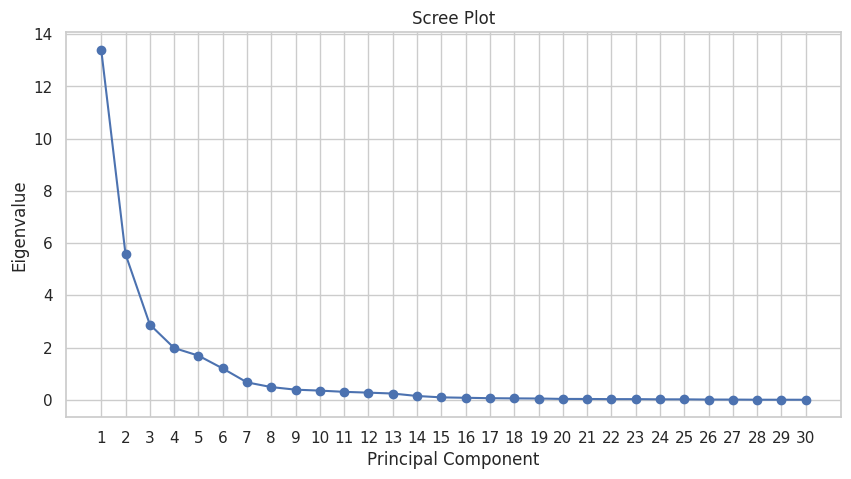

In [168]:
# ------------------------------------------------------------
# STEP 8: Scree Plot
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.plot(
    range(1, len(eigenvalues) + 1),
    eigenvalues,
    marker='o'
)

plt.xlabel("Principal Component")
plt.ylabel("Eigenvalue")
plt.title("Scree Plot")
plt.xticks(range(1, 31))
plt.grid(True)

plt.show()


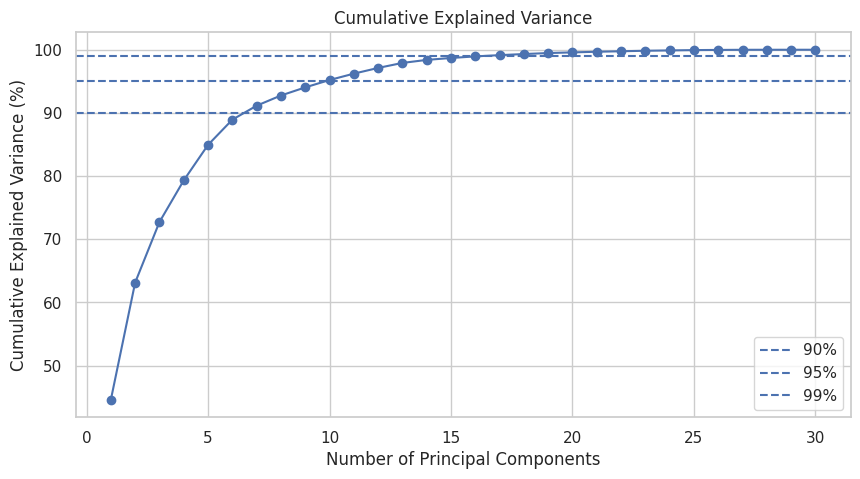

In [169]:
# STEP 9: Cumulative Explained Variance Plot
plt.figure(figsize=(10, 5))
plt.plot(
    range(1, len(eigenvalues) + 1),
    cumulative_explained_variance * 100,
    marker='o'
)
plt.axhline(
    y=90,
    linestyle='--',
    label='90%'
)
plt.axhline(
    y=95,
    linestyle='--',
    label='95%'
)
plt.axhline(
    y=99,
    linestyle='--',
    label='99%'
)
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.title("Cumulative Explained Variance")
plt.legend()
plt.grid(True)

plt.show()

##Conclusion-

PCA was performed from first principles using the eigenvalues obtained from the covariance matrix. The explained variance ratio and cumulative explained variance were calculated for all 30 principal components. The minimum numbers of components required to retain at least 90%, 95%, and 99% of the variance were identified as \(k_{90}\), \(k_{95}\), and \(k_{99}\), respectively. The scree plot and cumulative explained variance plot were used to visualize the variance distribution. The \(k_{95}\) value will be used for subsequent dimensionality-reduction experiments.

##06- Project and Visualise the Data in PCA Space


In [170]:
import seaborn as sns
#Eigenvector are already sorted in descending eigen order

V= eigenvectors

#PCA projection

X_train_pca= X_train_scaled @ V
X_test_pca= X_test_scaled @ V

print("Original training shape:", X_train_scaled.shape)
print("PCA projection shape:", X_train_pca.shape)

print("\nOriginal test shape:", X_test_scaled.shape)
print("PCA projection shape:", X_test_pca.shape)


Original training shape: (455, 30)
PCA projection shape: (455, 30)

Original test shape: (114, 30)
PCA projection shape: (114, 30)


In [171]:
X_train_pca_k95=X_train_pca[:,:k95]
X_test_pca_k95=X_test_pca[:,:k95]

print("PCA training shape at k95:" , X_train_pca_k95.shape)
print("PCA test shape at k95:" , X_test_pca_k95.shape)

PCA training shape at k95: (455, 10)
PCA test shape at k95: (114, 10)


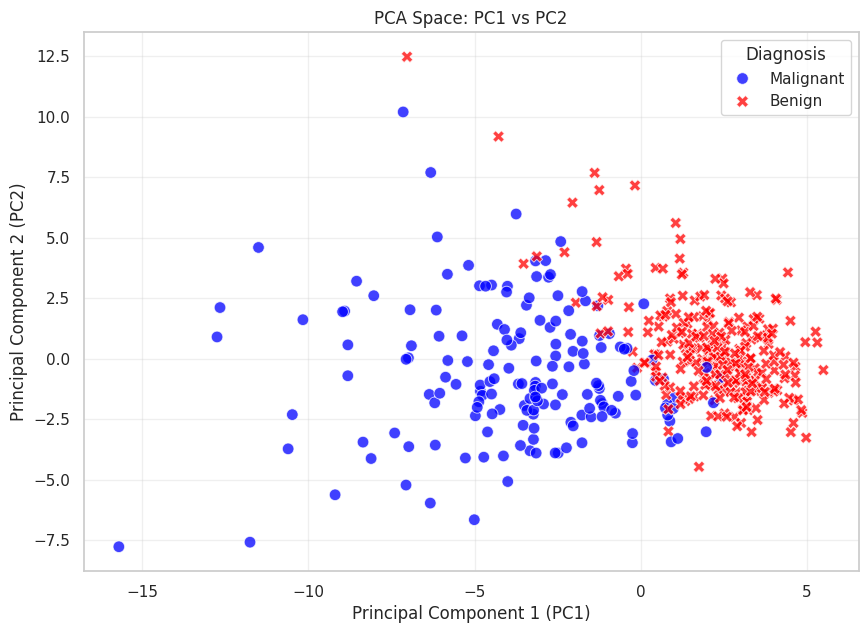

In [172]:
#PC1 vs PC2 Scatter plot

pca_plot_df=pd.DataFrame({
    "PC1":X_train_pca[:,0],
    "PC2":X_train_pca[:,1],
    "Diagnosis":y_train.map({
        0:"Benign",
        1:"Malignant"
    }).values
})

plt.figure(figsize=(10,7))
sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    style="Diagnosis",
    palette=["blue", "red"],
    s=70,
    alpha=0.75
)


plt.title("PCA Space: PC1 vs PC2")
plt.xlabel("Principal Component 1 (PC1)")
plt.ylabel("Principal Component 2 (PC2)")
plt.legend(title="Diagnosis")
plt.grid(True, alpha=0.3)

plt.show()

##Interpretation-

PC1 and PC2 do not completely separate the two diagnosis classes, although they may still capture important overall variance.

In [173]:
#Top 5 absolute loadings for PC1 and PC2
# ------------------------------------------------------------
# STEP 3: Top 5 absolute loadings for PC1 and PC2
# ------------------------------------------------------------

feature_names = X_train.columns

pc1_loadings = pd.Series(
    eigenvectors[:, 0],
    index=feature_names
)

pc2_loadings = pd.Series(
    eigenvectors[:, 1],
    index=feature_names
)

# Top 5 by absolute loading
top5_pc1 = pc1_loadings.reindex(
    pc1_loadings.abs().sort_values(ascending=False).head(5).index
)

top5_pc2 = pc2_loadings.reindex(
    pc2_loadings.abs().sort_values(ascending=False).head(5).index
)

print("Top 5 absolute loadings for PC1:")
print(top5_pc1)

print("\nTop 5 absolute loadings for PC2:")
print(top5_pc2)

Top 5 absolute loadings for PC1:
concave_points_mean    -0.260383
concavity_mean         -0.257761
concave_points_worst   -0.249367
compactness_mean       -0.241928
perimeter_worst        -0.235494
dtype: float64

Top 5 absolute loadings for PC2:
fractal_dimension_mean     0.366648
fractal_dimension_worst    0.277471
fractal_dimension_se       0.276203
radius_mean               -0.239776
area_mean                 -0.236925
dtype: float64


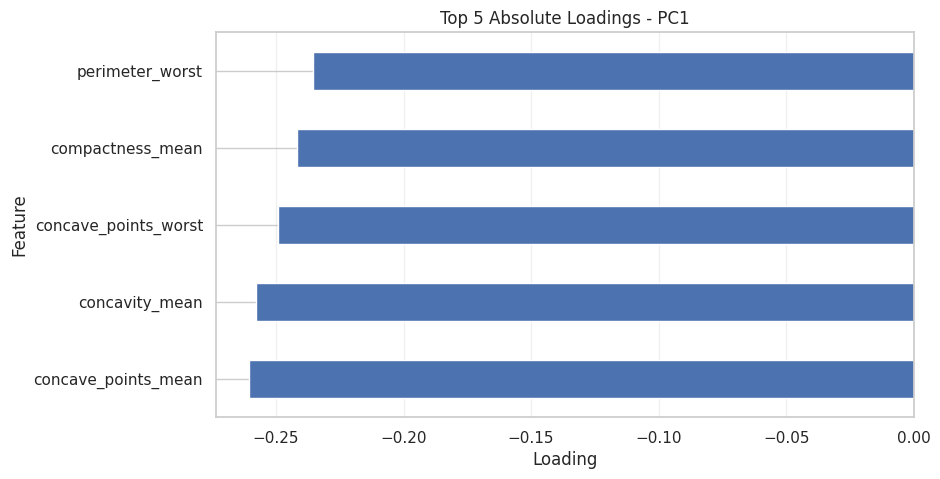

In [174]:

#Plot top 5 PC1 loadings

plt.figure(figsize=(9, 5))

top5_pc1.sort_values().plot(kind="barh")

plt.title("Top 5 Absolute Loadings - PC1")
plt.xlabel("Loading")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)

plt.show()

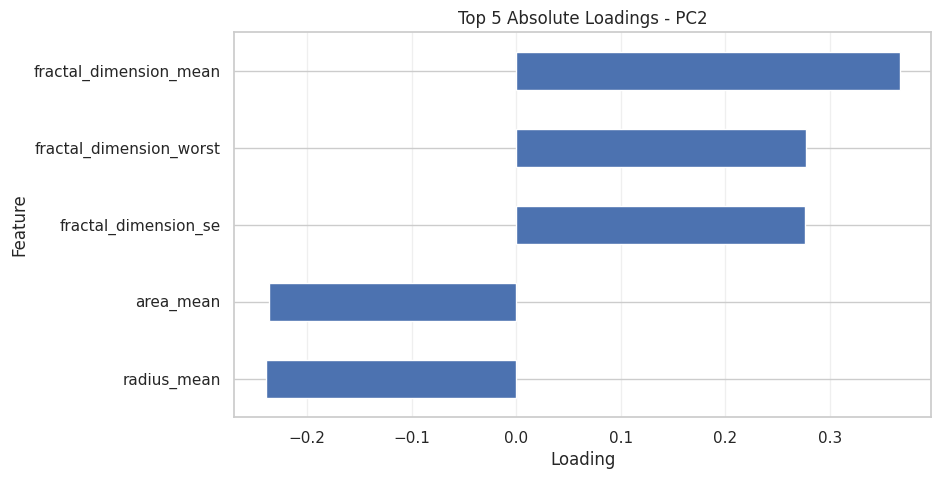

In [175]:
# Plot top 5 PC2 loadings


plt.figure(figsize=(9, 5))

top5_pc2.sort_values().plot(kind="barh")

plt.title("Top 5 Absolute Loadings - PC2")
plt.xlabel("Loading")
plt.ylabel("Feature")
plt.grid(axis="x", alpha=0.3)

plt.show()

In [176]:
#Loading summary table
loading_table=pd.DataFrame({
    "PC1 Loading": pc1_loadings,
    "PC1 |Loading|": pc1_loadings.abs(),
    "PC2 Loading": pc2_loadings,
    "PC2 |Loading|": pc2_loadings.abs()
})

loading_table=loading_table.sort_values(
    "PC1 |Loading|",
    ascending=False
)

print("Loading Summary :")
print(loading_table.head(10))



Loading Summary :
                      PC1 Loading  PC1 |Loading|  PC2 Loading  PC2 |Loading|
concave_points_mean     -0.260383       0.260383    -0.040533       0.040533
concavity_mean          -0.257761       0.257761     0.060089       0.060089
concave_points_worst    -0.249367       0.249367    -0.006525       0.006525
compactness_mean        -0.241928       0.241928     0.139921       0.139921
perimeter_worst         -0.235494       0.235494    -0.202365       0.202365
radius_worst            -0.226607       0.226607    -0.223083       0.223083
concavity_worst         -0.226322       0.226322     0.104547       0.104547
perimeter_mean          -0.225804       0.225804    -0.220949       0.220949
area_worst              -0.223108       0.223108    -0.223734       0.223734
area_mean               -0.219079       0.219079    -0.236925       0.236925


In [177]:
#Percent of variences in PC1 and PC2

pc1_variance = explained_variance_ratio[0] * 100
pc2_variance = explained_variance_ratio[1] * 100

print(f"PC1 explains {pc1_variance:.2f}% of the variance")
print(f"PC2 explains {pc2_variance:.2f}% of the variance")
print(f"PC1 + PC2 explain {(pc1_variance + pc2_variance):.2f}% of the variance")

PC1 explains 44.59% of the variance
PC2 explains 18.55% of the variance
PC1 + PC2 explain 63.14% of the variance


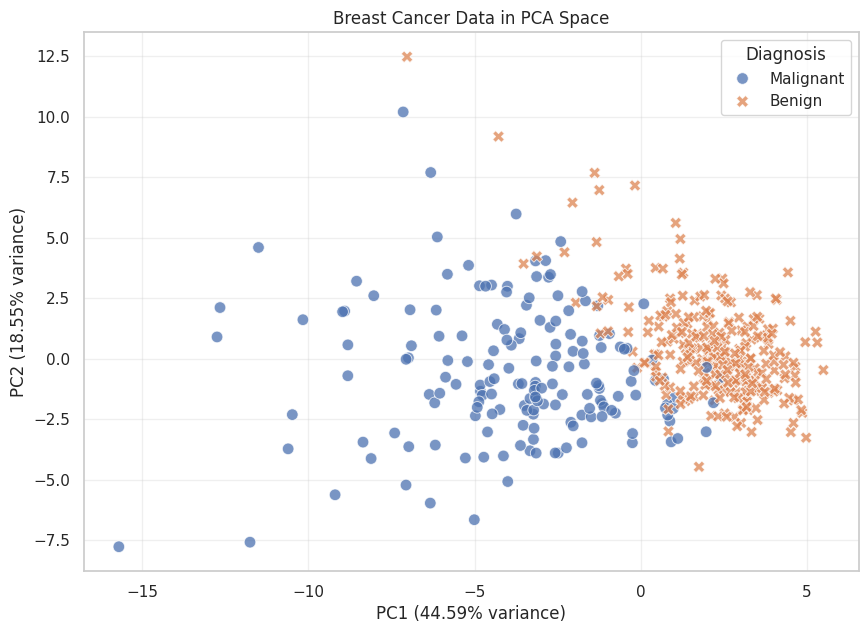

In [178]:
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=pca_plot_df,
    x="PC1",
    y="PC2",
    hue="Diagnosis",
    style="Diagnosis",
    s=70,
    alpha=0.75
)

plt.xlabel(f"PC1 ({pc1_variance:.2f}% variance)")
plt.ylabel(f"PC2 ({pc2_variance:.2f}% variance)")
plt.title("Breast Cancer Data in PCA Space")
plt.grid(True, alpha=0.3)
plt.show()

##Concluision-


The standardized training data was projected into PCA space using the eigenvectors obtained from the covariance matrix. The PC1–PC2 scatter plot was used to visualize the observations according to diagnosis. The distribution of benign and malignant observations indicates how well the first two principal components capture variation associated with the two diagnosis groups. The largest absolute loadings of PC1 and PC2 were also identified to determine which original features contribute most strongly to these principal components. PCA is an unsupervised dimensionality-reduction method, so the components maximize variance rather than directly maximizing class separation

##07- Verify the Manual PCA using Scikit-Learn

In [179]:
from sklearn.decomposition import PCA

# Scikit-learn PCA


pca_sklearn = PCA()
X_train_pca_sklearn = pca_sklearn.fit_transform(X_train_scaled)

# Eigenvalues from sklearn PCA
sklearn_eigenvalues = pca_sklearn.explained_variance_

# Explained variance ratio
sklearn_evr = pca_sklearn.explained_variance_ratio_

# Cumulative explained variance
sklearn_cumulative_evr = np.cumsum(sklearn_evr)

print("Scikit-learn PCA completed successfully.")
print("PCA transformed shape:", X_train_pca_sklearn.shape)

Scikit-learn PCA completed successfully.
PCA transformed shape: (455, 30)


In [180]:
# Compare first 10 eigenvalues

eigenvalue_comparison = pd.DataFrame({
    "PC": np.arange(1, 31),
    "Manual Eigenvalue": eigenvalues,
    "Sklearn Eigenvalue": sklearn_eigenvalues,
    "Absolute Difference": np.abs(
        eigenvalues - sklearn_eigenvalues
    )
})

print(eigenvalue_comparison.head(10))

   PC  Manual Eigenvalue  Sklearn Eigenvalue  Absolute Difference
0   1          13.407524           13.407524                  0.0
1   2           5.575831            5.575831                  0.0
2   3           2.881726            2.881726                  0.0
3   4           1.982488            1.982488                  0.0
4   5           1.690401            1.690401                  0.0
5   6           1.199182            1.199182                  0.0
6   7           0.665811            0.665811                  0.0
7   8           0.485268            0.485268                  0.0
8   9           0.386286            0.386286                  0.0
9  10           0.350469            0.350469                  0.0


In [181]:
#Compaire Variance Ratios

evr_comparison = pd.DataFrame({
    "PC": np.arange(1, 31),
    "Manual EVR": explained_variance_ratio,
    "Sklearn EVR": sklearn_evr,
    "Absolute Difference": np.abs(
        explained_variance_ratio - sklearn_evr
    )
})

print(evr_comparison.head(10))

   PC  Manual EVR  Sklearn EVR  Absolute Difference
0   1    0.445935     0.445935                  0.0
1   2    0.185453     0.185453                  0.0
2   3    0.095846     0.095846                  0.0
3   4    0.065938     0.065938                  0.0
4   5    0.056223     0.056223                  0.0
5   6    0.039885     0.039885                  0.0
6   7    0.022145     0.022145                  0.0
7   8    0.016140     0.016140                  0.0
8   9    0.012848     0.012848                  0.0
9  10    0.011657     0.011657                  0.0


In [182]:
max_evr_difference = np.max(
    np.abs(explained_variance_ratio - sklearn_evr)
)

print("Maximum EVR difference:", max_evr_difference)

Maximum EVR difference: 0.0


In [183]:
k95_sklearn = np.argmax(
    sklearn_cumulative_evr >= 0.95
) + 1

print("Manual PCA k95   :", k95)
print("Sklearn PCA k95  :", k95_sklearn)

Manual PCA k95   : 10
Sklearn PCA k95  : 10


In [184]:
## Manual eigenvectors:
# eigenvectors shape = (30, 30)
#
# sklearn components:
# pca_sklearn.components_ shape = (30, 30)

# Dot product between corresponding PCA directions
cosine_similarity = np.abs(
    np.sum(
        eigenvectors * pca_sklearn.components_.T,
        axis=0
    )
)

direction_comparison = pd.DataFrame({
    "PC": np.arange(1, 31),
    "Absolute Cosine Similarity": cosine_similarity
})

print(direction_comparison.head(10))

   PC  Absolute Cosine Similarity
0   1                         1.0
1   2                         1.0
2   3                         1.0
3   4                         1.0
4   5                         1.0
5   6                         1.0
6   7                         1.0
7   8                         1.0
8   9                         1.0
9  10                         1.0


In [185]:
#Whether th PCA directioins match or not
print(
    "Minimum cosine similarity:",
    cosine_similarity.min()
)

print(
    "Maximum cosine similarity:",
    cosine_similarity.max()
)

print(
    "Mean cosine similarity:",
    cosine_similarity.mean()
)

Minimum cosine similarity: 0.9999999999999987
Maximum cosine similarity: 1.0000000000000009
Mean cosine similarity: 0.9999999999999998


##Conclusion-

Manual PCA and Scikit-learn PCA should produce essentially identical eigenvalues and explained variance ratios, and they should identify the same k95. The PCA directions should also match up to a possible sign reversal of individual eigenvectors/components. Therefore, agreement between the two methods validates the manual PCA implementation.

##08: PCA Reconstruction and Information Loss


In [186]:
#origional standardized training data

Z = X_train_scaled

n, d = Z.shape

print("Original standardized data shape:", Z.shape)
print("Number of observations:", n)
print("Number of original features:", d)


Original standardized data shape: (455, 30)
Number of observations: 455
Number of original features: 30


In [187]:
#Select numbers of principle components
k_values = [2, 5, 10, k95, 20, 30]

# Remove duplicates and keep only valid values
k_values = sorted(set(k for k in k_values if 1 <= k <= d))

print("\nComponents selected for reconstruction:", k_values)


Components selected for reconstruction: [2, 5, 10, 20, 30]


In [188]:
#Reconstruct data and calculate MSE
reconstruction_results = []

for k in k_values:

    # Select the first k eigenvectors
    V_k = eigenvectors[:, :k]

    # Project original data into k-dimensional PCA space
    Z_pca_k = Z @ V_k

    # Reconstruct the data in the original 30-feature space
    Z_reconstructed = Z_pca_k @ V_k.T

    # Calculate reconstruction MSE
    mse = np.mean((Z - Z_reconstructed) ** 2)

    # Calculate retained variance
    retained_variance = np.sum(
        explained_variance_ratio[:k]
    )

    # Save results
    reconstruction_results.append({
        "Number of Components (k)": k,
        "Cumulative Explained Variance (%)":
            retained_variance * 100,
        "Reconstruction MSE": mse
    })

In [189]:
#Display results

reconstruction_df = pd.DataFrame(reconstruction_results)

print("\nPCA Reconstruction Results:")
display(reconstruction_df.round(6))



PCA Reconstruction Results:


,Number of Components (k),Cumulative Explained Variance (%),Reconstruction MSE
0,2,63.138778,0.368612
1,5,84.939473,0.150605
2,10,95.206910,0.047931
3,20,99.582766,0.004172
4,30,100.000000,0.000000


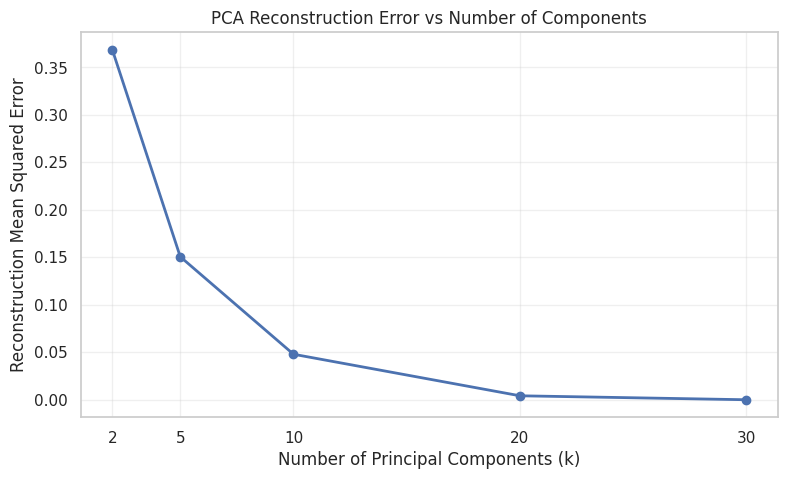

In [190]:
#Plot reconstruction MSE
plt.figure(figsize=(9, 5))

plt.plot(
    reconstruction_df["Number of Components (k)"],
    reconstruction_df["Reconstruction MSE"],
    marker="o",
    linewidth=2
)

plt.title("PCA Reconstruction Error vs Number of Components")
plt.xlabel("Number of Principal Components (k)")
plt.ylabel("Reconstruction Mean Squared Error")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)

plt.show()

## 09: Singular Value Decomposition from First Principles

In [191]:
##Obtain the standardized training matrix
Z = X_train_scaled

n, d = Z.shape

print("Original matrix Z shape:", Z.shape)
print("Number of observations:", n)
print("Number of features:", d)

Original matrix Z shape: (455, 30)
Number of observations: 455
Number of features: 30


In [192]:
#Perform SVD
U, S, Vt = np.linalg.svd(
    Z,
    full_matrices=False
)

# Construct diagonal Sigma matrix if needed
Sigma = np.diag(S)

print("\nSVD completed successfully.")

print("Shape of U:", U.shape)
print("Shape of S:", S.shape)
print("Shape of Sigma:", Sigma.shape)
print("Shape of Vt:", Vt.shape)


SVD completed successfully.
Shape of U: (455, 30)
Shape of S: (30,)
Shape of Sigma: (30, 30)
Shape of Vt: (30, 30)


In [193]:
#Display singular value
print("\nFirst 10 singular values:")
print(S[:10])

singular_value_table = pd.DataFrame({
    "Component": np.arange(1, len(S) + 1),
    "Singular Value": S,
    "Squared Singular Value": S ** 2
})

print("\nSingular Value Table:")
display(singular_value_table.head(10))


First 10 singular values:
[78.01932953 50.31329217 36.17047863 30.00082276 27.70274465 23.33299326
 17.38615303 14.84290302 13.24287328 12.61399139]

Singular Value Table:


,Component,Singular Value,Squared Singular Value
0,1,78.019330,6087.015781
1,2,50.313292,2531.427369
2,3,36.170479,1308.303525
3,4,30.000823,900.049366
4,5,27.702745,767.442061
5,6,23.332993,544.428574
6,7,17.386153,302.278317
7,8,14.842903,220.311770
8,9,13.242873,175.373693
9,10,12.613991,159.112779


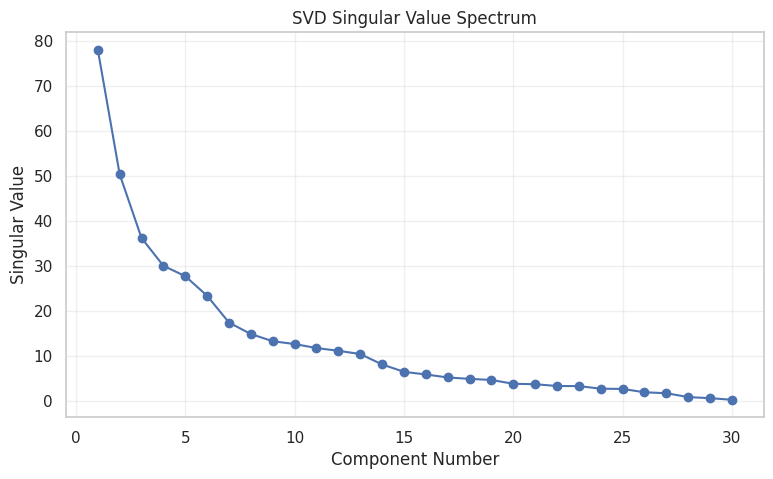

In [194]:
#Plot singular value spectrum

plt.figure(figsize=(9, 5))

plt.plot(
    np.arange(1, len(S) + 1),
    S,
    marker="o"
)

plt.title("SVD Singular Value Spectrum")
plt.xlabel("Component Number")
plt.ylabel("Singular Value")
plt.grid(True, alpha=0.3)

plt.show()

In [195]:
#Verify PCA eigen value by SVD
svd_eigenvalues = (S ** 2) / (n - 1)

print("\nFirst 10 manual PCA eigenvalues:")
print(eigenvalues[:10])

print("\nFirst 10 eigenvalues calculated from SVD:")
print(svd_eigenvalues[:10])

# Compare the eigenvalues
eigenvalue_difference = np.abs(
    eigenvalues - svd_eigenvalues
)

print(
    "\nMaximum eigenvalue difference:",
    np.max(eigenvalue_difference)
)


First 10 manual PCA eigenvalues:
[13.40752375  5.57583121  2.88172583  1.98248759  1.69040102  1.19918188
  0.66581127  0.48526822  0.38628567  0.35046868]

First 10 eigenvalues calculated from SVD:
[13.40752375  5.57583121  2.88172583  1.98248759  1.69040102  1.19918188
  0.66581127  0.48526822  0.38628567  0.35046868]

Maximum eigenvalue difference: 1.4210854715202004e-14


In [196]:
#Verify reconstruction Z= U sigma V t
Z_reconstructed = U @ Sigma @ Vt

reconstruction_error = np.linalg.norm(
    Z - Z_reconstructed,
    ord="fro"
)

print(
    "\nSVD reconstruction Frobenius error:",
    reconstruction_error
)


SVD reconstruction Frobenius error: 1.726799667967889e-13


In [197]:
#Verify orthogonality
U_orthogonality_error = np.linalg.norm(
    U.T @ U - np.eye(U.shape[1]),
    ord="fro"
)

V_orthogonality_error = np.linalg.norm(
    Vt @ Vt.T - np.eye(Vt.shape[0]),
    ord="fro"
)

print(
    "\nU orthogonality error:",
    U_orthogonality_error
)
print(
    "V orthogonality error:",
    V_orthogonality_error
)


U orthogonality error: 6.9849303218503494e-15
V orthogonality error: 7.810307785549551e-15


In [198]:
#Compare PCA eigenvectors with SVD vectors

V_svd = Vt.T

# Absolute cosine similarity for corresponding directions
cosine_similarity = np.abs(
    np.sum(eigenvectors * V_svd, axis=0)
)

direction_comparison = pd.DataFrame({
    "Component": np.arange(1, d + 1),
    "Absolute Cosine Similarity": cosine_similarity
})

print("\nPCA and SVD direction comparison:")
display(direction_comparison.head(10))


print(
    "\nMinimum absolute cosine similarity:",
    cosine_similarity.min()
)

print(
    "Mean absolute cosine similarity:",
    cosine_similarity.mean()
)


PCA and SVD direction comparison:


,Component,Absolute Cosine Similarity
0,1,1.0
1,2,1.0
2,3,1.0
3,4,1.0
4,5,1.0
5,6,1.0
6,7,1.0
7,8,1.0
8,9,1.0
9,10,1.0



Minimum absolute cosine similarity: 0.9999999999999991
Mean absolute cosine similarity: 1.0


##10: Truncated SVD and Low-Rank Reconstruction

In [199]:
#Origional Standardize trainig set

Z = X_train_scaled

n, d = Z.shape

print("Original data shape:", Z.shape)


# Step 2: Select the number of components


k_values = [2, 5, 10, k95, 20, 30]

# Remove duplicates and keep valid component counts
k_values = sorted(set(k for k in k_values if 1 <= k <= d))

print("Selected component counts:", k_values)

Original data shape: (455, 30)
Selected component counts: [2, 5, 10, 20, 30]


In [200]:
#Perform truncate SVD reconstruction

svd_results = []

for k in k_values:

    # Truncate the SVD matrices
    U_k = U[:, :k]
    S_k = S[:k]
    Vt_k = Vt[:k, :]

    # Construct the diagonal singular-value matrix
    Sigma_k = np.diag(S_k)

    # Reconstruct the standardized data
    Z_svd_reconstructed = U_k @ Sigma_k @ Vt_k

    # Calculate reconstruction MSE
    svd_mse = np.mean(
        (Z - Z_svd_reconstructed) ** 2
    )

    # Calculate cumulative explained variance
    retained_variance = np.sum(
        explained_variance_ratio[:k]
    )

    svd_results.append({
        "k": k,
        "Cumulative Explained Variance (%)":
            retained_variance * 100,
        "SVD Reconstruction MSE": svd_mse
    })


In [201]:
#Display SVD reconstruction result
svd_df = pd.DataFrame(svd_results)

print("\nTruncated SVD Reconstruction Results:")
display(svd_df.round(8))


Truncated SVD Reconstruction Results:


,k,Cumulative Explained Variance (%),SVD Reconstruction MSE
0,2,63.138778,0.368612
1,5,84.939473,0.150605
2,10,95.206910,0.047931
3,20,99.582766,0.004172
4,30,100.000000,0.000000


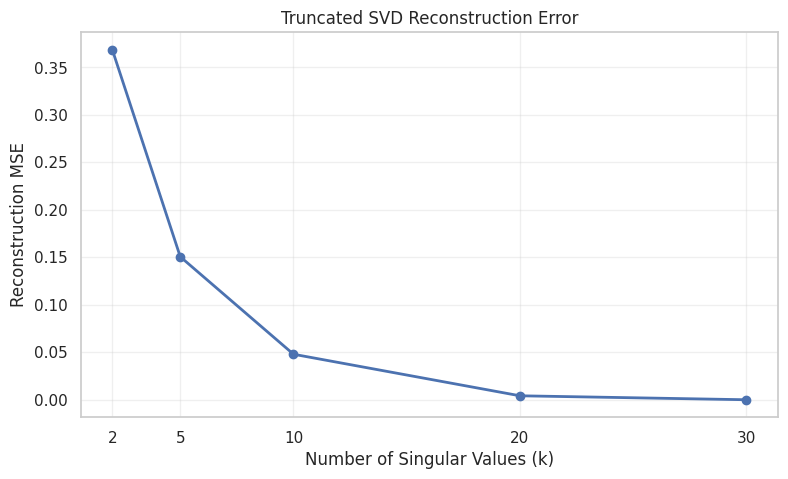

In [202]:
#Plot SVD recontruction MSE
plt.figure(figsize=(9, 5))

plt.plot(
    svd_df["k"],
    svd_df["SVD Reconstruction MSE"],
    marker="o",
    linewidth=2
)

plt.title("Truncated SVD Reconstruction Error")
plt.xlabel("Number of Singular Values (k)")
plt.ylabel("Reconstruction MSE")
plt.xticks(k_values)
plt.grid(True, alpha=0.3)

plt.show()

In [203]:
#PCA vs SVD reconstruction Comparision
comparison_results = []

for k in k_values:

    # -----------------------------
    # PCA reconstruction
    # -----------------------------

    V_k = eigenvectors[:, :k]

    Z_pca_k = Z @ V_k

    Z_pca_reconstructed = Z_pca_k @ V_k.T

    mse_pca = np.mean(
        (Z - Z_pca_reconstructed) ** 2
    )
    #SVD reconstruction

    U_k = U[:, :k]
    Sigma_k = np.diag(S[:k])
    Vt_k = Vt[:k, :]

    Z_svd_reconstructed = U_k @ Sigma_k @ Vt_k

    mse_svd = np.mean(
        (Z - Z_svd_reconstructed) ** 2
    )
# Cumulative explained varience
    cumulative_variance = np.sum(
        explained_variance_ratio[:k]
    )

    comparison_results.append({
        "k": k,
        "Cumulative Explained Variance (%)":
            cumulative_variance * 100,
        "PCA Reconstruction MSE": mse_pca,
        "SVD Reconstruction MSE": mse_svd,
        "Absolute MSE Difference":
            abs(mse_pca - mse_svd)
    })

#Create comparision table

comparison_df = pd.DataFrame(comparison_results)

print("PCA vs SVD Reconstruction Comparison:")
display(comparison_df.round(10))


PCA vs SVD Reconstruction Comparison:


,k,Cumulative Explained Variance (%),PCA Reconstruction MSE,SVD Reconstruction MSE,Absolute MSE Difference
0,2,63.138778,0.368612,0.368612,0.0
1,5,84.939473,0.150605,0.150605,0.0
2,10,95.206910,0.047931,0.047931,0.0
3,20,99.582766,0.004172,0.004172,0.0
4,30,100.000000,0.000000,0.000000,0.0


##What is low - rank approximation?
sol.Low-rank approximation represents a high-dimensional matrix using fewer components while preserving as much of its variation as possible.

For this dataset:
- Original representation: 30 features.
- Rank-5 approximation: 5 retained components.
- Rank-10 approximation: 10 retained components.
- Rank-30 reconstruction: all 30 components retained.
Lower ranks provide greater dimensionality reduction but generally produce greater reconstruction error.

##11: Feature Selection Using ANOVA and Mutual Information

In [204]:
from sklearn.feature_selection import (
    SelectKBest,
    f_classif,
    mutual_info_classif
)

In [205]:
#prepare training data
X_train_fs = X_train.copy()
y_train_fs = y_train.copy()

feature_names = X_train_fs.columns

print("Training feature matrix shape:", X_train_fs.shape)
print("Training target shape:", y_train_fs.shape)
print("Number of original features:", len(feature_names))
print("k95 from Task 5:", k95)

Training feature matrix shape: (455, 30)
Training target shape: (455,)
Number of original features: 30
k95 from Task 5: 10


In [206]:
#feature selection using ANOVA f-score
anova_selector = SelectKBest(
    score_func=f_classif,
    k=k95
)

X_train_anova = anova_selector.fit_transform(
    X_train_fs,
    y_train_fs
)

# Get all ANOVA F-scores
anova_scores = anova_selector.scores_

# Arrange features from highest to lowest F-score
anova_ranking = pd.DataFrame({
    "Feature": feature_names,
    "ANOVA F-Score": anova_scores
}).sort_values(
    by="ANOVA F-Score",
    ascending=False
).reset_index(drop=True)

# Extract top k95 features
anova_selected_features = (
    anova_ranking["Feature"].head(k95).tolist()
)

print("\nANOVA-selected feature matrix shape:")
print(X_train_anova.shape)

print("\nTop 10 features according to ANOVA:")
display(anova_ranking.head(10).round(4))


ANOVA-selected feature matrix shape:
(455, 10)

Top 10 features according to ANOVA:


,Feature,ANOVA F-Score
0,concave_points_worst,733.7249
1,perimeter_worst,717.2465
2,radius_worst,692.8614
3,concave_points_mean,684.5268
4,perimeter_mean,548.4132
5,area_worst,522.1889
6,radius_mean,511.2748
7,area_mean,444.8575
8,concavity_mean,397.5921
9,concavity_worst,319.5078


In [207]:
#feature selection using Mutual information
mi_scores = mutual_info_classif(
    X_train_fs,
    y_train_fs,
    random_state=42
)

mi_ranking = pd.DataFrame({
    "Feature": feature_names,
    "Mutual Information": mi_scores
}).sort_values(
    by="Mutual Information",
    ascending=False
).reset_index(drop=True)

# Extract top k95 features
mi_selected_features = (
    mi_ranking["Feature"].head(k95).tolist()
)

# Transform training data using the MI-selected columns
X_train_mi = X_train_fs[mi_selected_features]

print("\nMI-selected feature matrix shape:")
print(X_train_mi.shape)

print("\nTop 10 features according to Mutual Information:")
display(mi_ranking.head(10).round(4))


MI-selected feature matrix shape:
(455, 10)

Top 10 features according to Mutual Information:


,Feature,Mutual Information
0,radius_worst,0.4612
1,perimeter_worst,0.4546
2,area_worst,0.4533
3,concave_points_mean,0.4460
4,concave_points_worst,0.4329
5,perimeter_mean,0.4093
6,area_mean,0.3747
7,radius_mean,0.3733
8,concavity_mean,0.3541
9,area_se,0.3500


In [208]:
#Compare the top 10 feature
top10_anova = set(anova_ranking["Feature"].head(10))
top10_mi = set(mi_ranking["Feature"].head(10))

common_top10 = top10_anova.intersection(top10_mi)

print("\nTop 10 ANOVA features:")
print(anova_ranking["Feature"].head(10).tolist())

print("\nTop 10 MI features:")
print(mi_ranking["Feature"].head(10).tolist())

print("\nFeatures common to both top-10 lists:")
print(sorted(common_top10))
print("\nNumber of common top-10 features:")
print(len(common_top10))


Top 10 ANOVA features:
['concave_points_worst', 'perimeter_worst', 'radius_worst', 'concave_points_mean', 'perimeter_mean', 'area_worst', 'radius_mean', 'area_mean', 'concavity_mean', 'concavity_worst']

Top 10 MI features:
['radius_worst', 'perimeter_worst', 'area_worst', 'concave_points_mean', 'concave_points_worst', 'perimeter_mean', 'area_mean', 'radius_mean', 'concavity_mean', 'area_se']

Features common to both top-10 lists:
['area_mean', 'area_worst', 'concave_points_mean', 'concave_points_worst', 'concavity_mean', 'perimeter_mean', 'perimeter_worst', 'radius_mean', 'radius_worst']

Number of common top-10 features:
9


In [209]:
#Calculate Jaccard similarity
union_top10 = top10_anova.union(top10_mi)

jaccard_similarity = (
    len(common_top10) / len(union_top10)
    if union_top10 else 0
)

print("\nJaccard similarity between top-10 lists:")
print(round(jaccard_similarity, 4))


Jaccard similarity between top-10 lists:
0.8182


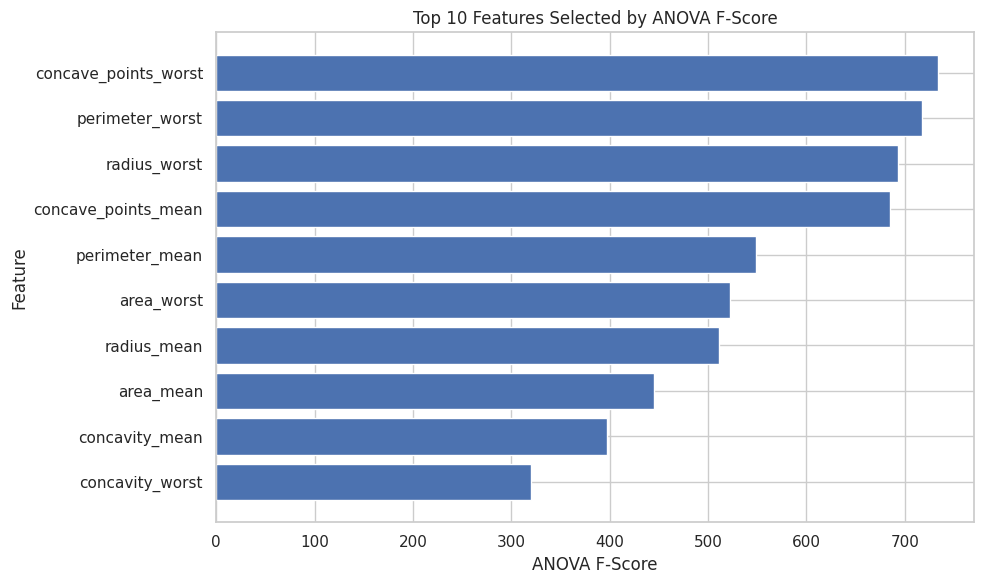

In [210]:
#plot th etop 10 ANOVA features
plt.figure(figsize=(10, 6))

anova_plot = anova_ranking.head(10).sort_values(
    "ANOVA F-Score"
)

plt.barh(
    anova_plot["Feature"],
    anova_plot["ANOVA F-Score"]
)

plt.title("Top 10 Features Selected by ANOVA F-Score")
plt.xlabel("ANOVA F-Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

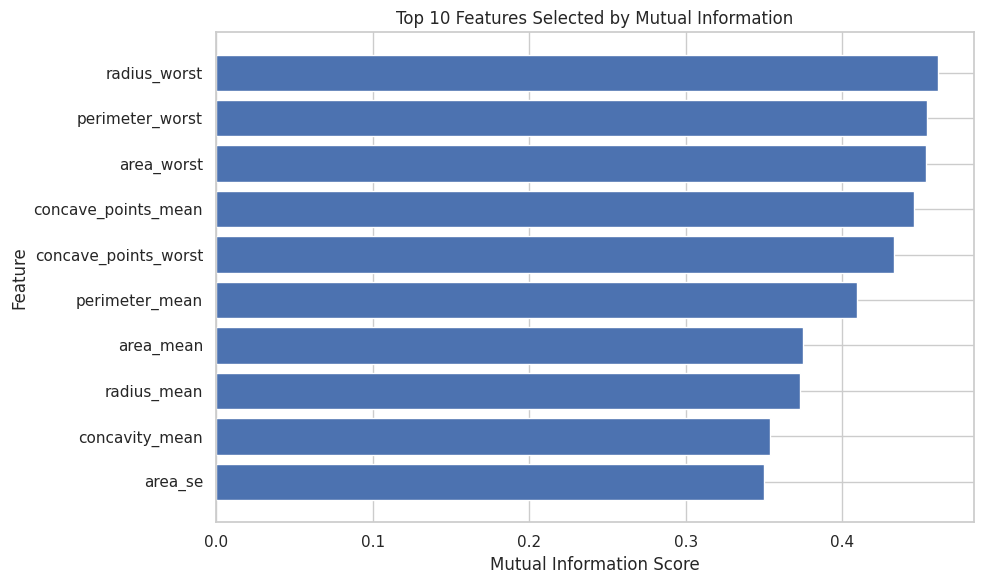

In [211]:
#Plot top 10 mutual Information features
plt.figure(figsize=(10, 6))

mi_plot = mi_ranking.head(10).sort_values(
    "Mutual Information"
)

plt.barh(
    mi_plot["Feature"],
    mi_plot["Mutual Information"]
)

plt.title("Top 10 Features Selected by Mutual Information")
plt.xlabel("Mutual Information Score")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [212]:
#Display selected feature list
selected_features_comparison = pd.DataFrame({
    "ANOVA Selected Features": pd.Series(
        anova_selected_features
    ),
    "MI Selected Features": pd.Series(
        mi_selected_features
    )
})

print("\nSelected feature comparison:")
display(selected_features_comparison)


Selected feature comparison:


,ANOVA Selected Features,MI Selected Features
0,concave_points_worst,radius_worst
1,perimeter_worst,perimeter_worst
2,radius_worst,area_worst
3,concave_points_mean,concave_points_mean
4,perimeter_mean,concave_points_worst
5,area_worst,perimeter_mean
6,radius_mean,area_mean
7,area_mean,radius_mean
8,concavity_mean,concavity_mean
9,concavity_worst,area_se


In [213]:
# ANOVA-selected features
X_train_anova_selected = X_train[
    anova_selected_features
]

X_test_anova_selected = X_test[
    anova_selected_features
]

# MI-selected features
X_train_mi_selected = X_train[
    mi_selected_features
]

X_test_mi_selected = X_test[
    mi_selected_features
]

print("ANOVA training shape:", X_train_anova_selected.shape)
print("ANOVA testing shape:", X_test_anova_selected.shape)

print("MI training shape:", X_train_mi_selected.shape)
print("MI testing shape:", X_test_mi_selected.shape)

ANOVA training shape: (455, 10)
ANOVA testing shape: (114, 10)
MI training shape: (455, 10)
MI testing shape: (114, 10)


##12: Feature Extraction Versus Feature Selection

In [214]:
#Origional Standardize data
Z_train = X_train_scaled
Z_test = X_test_scaled

n_train, n_features = Z_train.shape

print("Original training shape:", Z_train.shape)
print("Original testing shape:", Z_test.shape)
print("Number of original features:", n_features)
print("k95:", k95)

#Origional representation
X_train_original = Z_train
X_test_original = Z_test

Original training shape: (455, 30)
Original testing shape: (114, 30)
Number of original features: 30
k95: 10


In [215]:
#PCA Representation
V_pca_k95 = eigenvectors[:, :k95]

X_train_pca_k95 = Z_train @ V_pca_k95
X_test_pca_k95 = Z_test @ V_pca_k95


In [216]:
#SVD representation

# Vt contains the right singular vectors as rows
V_svd_k95 = Vt[:k95, :].T

X_train_svd_k95 = X_train_scaled @ V_svd_k95
X_test_svd_k95 = X_test_scaled @ V_svd_k95

print("SVD training dimensions:", X_train_svd_k95.shape)
print("SVD testing dimensions:", X_test_svd_k95.shape)

SVD training dimensions: (455, 10)
SVD testing dimensions: (114, 10)


In [217]:
#ANOVA feature selection
X_train_anova_k95 = X_train[
    anova_selected_features
]

X_test_anova_k95 = X_test[
    anova_selected_features
]

# Standardize selected ANOVA features using training data
from sklearn.preprocessing import StandardScaler

scaler_anova = StandardScaler()

X_train_anova_k95_scaled = scaler_anova.fit_transform(
    X_train_anova_k95
)

X_test_anova_k95_scaled = scaler_anova.transform(
    X_test_anova_k95
)

In [218]:
#Mutual Information feature selection
X_train_mi_k95 = X_train[
    mi_selected_features
]

X_test_mi_k95 = X_test[
    mi_selected_features
]

# Standardize selected MI features using training data
scaler_mi = StandardScaler()

X_train_mi_k95_scaled = scaler_mi.fit_transform(
    X_train_mi_k95
)
X_test_mi_k95_scaled = scaler_mi.transform(
    X_test_mi_k95
)


In [219]:
#Create representation comaprison table
representations = [
    {
        "Representation": "Original 30 Features",
        "Training Dimensions": X_train_original.shape[1],
        "Testing Dimensions": X_test_original.shape[1],
        "Method Type": "Original representation"
    },
    {
        "Representation": "PCA k95",
        "Training Dimensions": X_train_pca_k95.shape[1],
        "Testing Dimensions": X_test_pca_k95.shape[1],
        "Method Type": "Feature extraction"
    },
    {
        "Representation": "SVD k95",
        "Training Dimensions": X_train_svd_k95.shape[1],
        "Testing Dimensions": X_test_svd_k95.shape[1],
        "Method Type": "Feature extraction"
    },
    {
        "Representation": "ANOVA k95",
        "Training Dimensions": X_train_anova_k95_scaled.shape[1],
        "Testing Dimensions": X_test_anova_k95_scaled.shape[1],
        "Method Type": "Feature selection"
    },
    {
         "Representation": "MI k95",
        "Training Dimensions": X_train_mi_k95_scaled.shape[1],
        "Testing Dimensions": X_test_mi_k95_scaled.shape[1],
        "Method Type": "Feature selection"
    }
]

representation_df = pd.DataFrame(representations)

print("\nRepresentation Comparison:")
display(representation_df)


Representation Comparison:


,Representation,Training Dimensions,Testing Dimensions,Method Type
0,Original 30 Features,30,30,Original representation
1,PCA k95,10,10,Feature extraction
2,SVD k95,10,10,Feature extraction
3,ANOVA k95,10,10,Feature selection
4,MI k95,10,10,Feature selection


In [220]:
#Display selected origional feature
print("\nANOVA-selected features:")
print(anova_selected_features)

print("\nMI-selected features:")
print(mi_selected_features)


ANOVA-selected features:
['concave_points_worst', 'perimeter_worst', 'radius_worst', 'concave_points_mean', 'perimeter_mean', 'area_worst', 'radius_mean', 'area_mean', 'concavity_mean', 'concavity_worst']

MI-selected features:
['radius_worst', 'perimeter_worst', 'area_worst', 'concave_points_mean', 'concave_points_worst', 'perimeter_mean', 'area_mean', 'radius_mean', 'concavity_mean', 'area_se']


In [221]:
#Calculate dimensionality reduction percentage

reduction_pca = (
    (n_features - k95) / n_features
) * 100

reduction_svd = (
    (n_features - k95) / n_features
) * 100

reduction_anova = (
    (n_features - len(anova_selected_features))
    / n_features
) * 100

reduction_mi = (
    (n_features - len(mi_selected_features))
    / n_features
) * 100

print("\nDimensionality Reduction:")
print(f"PCA:   {reduction_pca:.2f}%")
print(f"SVD:   {reduction_svd:.2f}%")
print(f"ANOVA: {reduction_anova:.2f}%")
print(f"MI:    {reduction_mi:.2f}%")



Dimensionality Reduction:
PCA:   66.67%
SVD:   66.67%
ANOVA: 66.67%
MI:    66.67%


##Which approach preserves the most useful diagnostic information?
Sol.You cannot establish this from variance retention or feature scores alone. A PCA representation that preserves 95% of total variance is not guaranteed to provide the best classification performance.

##Interpretation:-
Feature extraction and feature selection were compared using PCA, SVD, ANOVA F-score, and Mutual Information. PCA and SVD create new features by projecting the standardized data into a lower-dimensional space, whereas ANOVA and MI select subsets of the original features using diagnosis labels. All four methods can reduce dimensionality, but feature selection retains the original feature meanings and is generally easier to interpret. PCA and SVD can capture combinations of correlated features, making them useful when reducing redundancy. The most suitable method should ultimately be assessed using both dimensionality and classification performance.

##13: Controlled Dimensionality Sweep

In [222]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score
)

In [223]:
#Define the number of PCA components
n_features = X_train_pca.shape[1]

k_values = sorted(set(
    k for k in [2, 5, 10, k95, 20, 30]
    if 1 <= k <= n_features
))

print("Number of PCA components to test:", k_values)
print("k95 =", k95)


Number of PCA components to test: [2, 5, 10, 20, 30]
k95 = 10


In [224]:
#Train logistic regression for each k
results = []

for k in k_values:

    # Select the first k principal components
    X_train_k = X_train_pca[:, :k]
    X_test_k = X_test_pca[:, :k]

    # Train the model
    model = LogisticRegression(
        max_iter=10000,
        random_state=42
    )
    model.fit(X_train_k, y_train)

    # Predictions
    y_pred = model.predict(X_test_k)

    # Probability of malignant diagnosis (class 1)
    y_prob = model.predict_proba(X_test_k)[:, 1]

    # Evaluation metrics
    accuracy = accuracy_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

     # Cumulative explained variance
    variance_retained = np.sum(
        explained_variance_ratio[:k]
    )

    # Store results
    results.append({
        "Components (k)": k,
        "Cumulative Explained Variance (%)":
            variance_retained * 100,
        "Accuracy": accuracy,
        "F1-Score": f1,
        "ROC-AUC": roc_auc
    })

In [225]:
# Display the results
results_df = pd.DataFrame(results)

print("\n DIMENSIONALITY SWEEP RESULTS")
display(results_df.round(4))


 DIMENSIONALITY SWEEP RESULTS


,Components (k),Cumulative Explained Variance (%),Accuracy,F1-Score,ROC-AUC
0,2,63.1388,0.9474,0.9250,0.9964
1,5,84.9395,0.9737,0.9639,0.9964
2,10,95.2069,0.9737,0.9630,0.9970
3,20,99.5828,0.9649,0.9512,0.9967
4,30,100.0000,0.9649,0.9512,0.9960


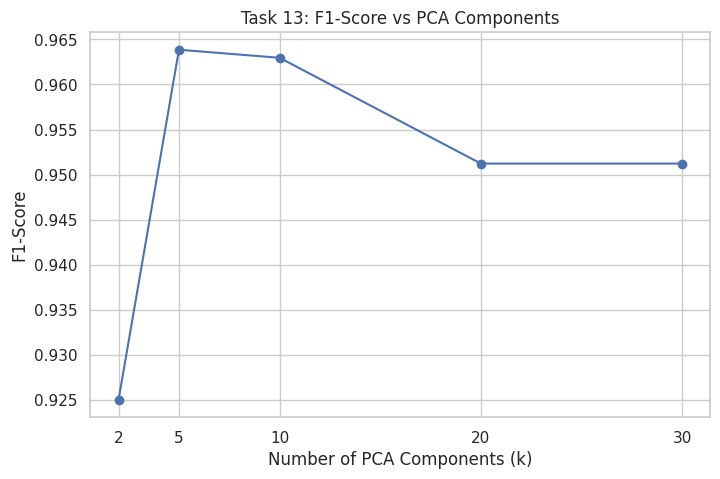

In [226]:
# Plot F1-score against the number of PCA components

plt.figure(figsize=(8, 5))

plt.plot(
    results_df["Components (k)"],
    results_df["F1-Score"],
    marker="o"
)

plt.xlabel("Number of PCA Components (k)")
plt.ylabel("F1-Score") # Of logistice regression
plt.title("Task 13: F1-Score vs PCA Components")
plt.xticks(results_df["Components (k)"])
plt.grid(True)

plt.show()

##Interpretation-
1. X-axis: Number of principal components used.

2. Y-axis: F1-score of Logistic Regression.

3. A higher F1-score indicates a better balance between precision and recall.

4. A sharp improvement at smaller values of \(k\) suggests that a relatively small number of components captures useful classification information.

5. If the F1-score decreases after adding components, the additional components may contribute variance without improving classification at the chosen decision threshold.

##Q1. Does retaining more variance always guarantee better classification performance?
Sol.No.

PCA selects components based on how much variance they explain, not how useful they are for predicting the diagnosis.

A component with high variance may capture differences in measurements that are not strongly related to whether a tumour is benign or malignant. A component with lower variance may still contain useful diagnostic information.

Therefore, retaining more variance does not guarantee a higher Accuracy, F1-score, or ROC-AUC.

##14: Downstream Model Comparison

In [227]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

In [228]:
# Define the five feature representations
representations = {
    "Original (30 features)": (
        X_train_scaled,
        X_test_scaled
    ),

    "PCA k95": (
        X_train_pca_k95,
        X_test_pca_k95
    ),
    "SVD k95": (
        X_train_svd_k95,
        X_test_svd_k95
    ),

    "ANOVA k95": (
        X_train_anova_k95_scaled,
        X_test_anova_k95_scaled
    ),
    "MI k95": (
        X_train_mi_k95_scaled,
        X_test_mi_k95_scaled
    )
}


In [229]:
# Define classification models

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=10000,
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    )
}


In [230]:
# Train and evaluate every combination
results = []

for representation_name, (Xtr, Xte) in representations.items():

    for model_name, model_template in models.items():

        # Create a fresh model for each experiment
        from sklearn.base import clone
        model = clone(model_template)
        # Train the model
        model.fit(Xtr, y_train)

        # Predict class labels
        y_pred = model.predict(Xte)

        # Find the probability of malignant class (1)
        y_prob = model.predict_proba(Xte)[:, 1]

        # Calculate evaluation metrics
        accuracy = accuracy_score(y_test, y_pred)

        precision = precision_score(
            y_test, y_pred, zero_division=0
        )

        recall = recall_score(
            y_test, y_pred, zero_division=0
        )

        f1 = f1_score(
            y_test, y_pred, zero_division=0
        )
        roc_auc = roc_auc_score(y_test, y_prob)

        # Store results
        results.append({
            "Representation": representation_name,
            "Model": model_name,
            "Features": Xtr.shape[1],
            "Accuracy": accuracy,
            "Precision": precision,
            "Recall": recall,
            "F1-Score": f1,
            "ROC-AUC": roc_auc
        })


In [231]:
# Display comparision table
results_df = pd.DataFrame(results)

print(" DOWNSTREAM MODEL COMPARISON")

display(
    results_df.round(4)
)

 DOWNSTREAM MODEL COMPARISON


,Representation,Model,Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Original (30 features),Logistic Regression,30,0.9649,0.9750,0.9286,0.9512,0.9960
1,Original (30 features),KNN,30,0.9561,0.9744,0.9048,0.9383,0.9823
2,PCA k95,Logistic Regression,10,0.9737,1.0000,0.9286,0.9630,0.9970
3,PCA k95,KNN,10,0.9561,0.9744,0.9048,0.9383,0.9838
4,SVD k95,Logistic Regression,10,0.9737,1.0000,0.9286,0.9630,0.9970
5,SVD k95,KNN,10,0.9561,0.9744,0.9048,0.9383,0.9838
6,ANOVA k95,Logistic Regression,10,0.9561,0.9744,0.9048,0.9383,0.9974
7,ANOVA k95,KNN,10,0.9561,1.0000,0.8810,0.9367,0.9962
8,MI k95,Logistic Regression,10,0.9649,0.9750,0.9286,0.9512,0.9977
9,MI k95,KNN,10,0.9474,0.9737,0.8810,0.9250,0.9955


In [232]:
# Sort result by F1 score
print("Models ranked by F1-score:")

ranked_results = results_df.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(ranked_results.round(4))

Models ranked by F1-score:


,Representation,Model,Features,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,SVD k95,Logistic Regression,10,0.9737,1.0000,0.9286,0.9630,0.9970
1,PCA k95,Logistic Regression,10,0.9737,1.0000,0.9286,0.9630,0.9970
2,MI k95,Logistic Regression,10,0.9649,0.9750,0.9286,0.9512,0.9977
3,Original (30 features),Logistic Regression,30,0.9649,0.9750,0.9286,0.9512,0.9960
4,Original (30 features),KNN,30,0.9561,0.9744,0.9048,0.9383,0.9823
5,PCA k95,KNN,10,0.9561,0.9744,0.9048,0.9383,0.9838
6,SVD k95,KNN,10,0.9561,0.9744,0.9048,0.9383,0.9838
7,ANOVA k95,Logistic Regression,10,0.9561,0.9744,0.9048,0.9383,0.9974
8,ANOVA k95,KNN,10,0.9561,1.0000,0.8810,0.9367,0.9962
9,MI k95,KNN,10,0.9474,0.9737,0.8810,0.9250,0.9955


In [233]:
# Identify best model for each metric
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC"
]

print("Best result for each metric:")

for metric in metrics:
    best_index = results_df[metric].idxmax()
    best_row = results_df.loc[best_index]

    print(
        f"{metric}: {best_row['Model']} using "
        f"{best_row['Representation']} = "
        f"{best_row[metric]:.4f}"
    )

Best result for each metric:
Accuracy: Logistic Regression using PCA k95 = 0.9737
Precision: Logistic Regression using PCA k95 = 1.0000
Recall: Logistic Regression using Original (30 features) = 0.9286
F1-Score: Logistic Regression using PCA k95 = 0.9630
ROC-AUC: Logistic Regression using MI k95 = 0.9977


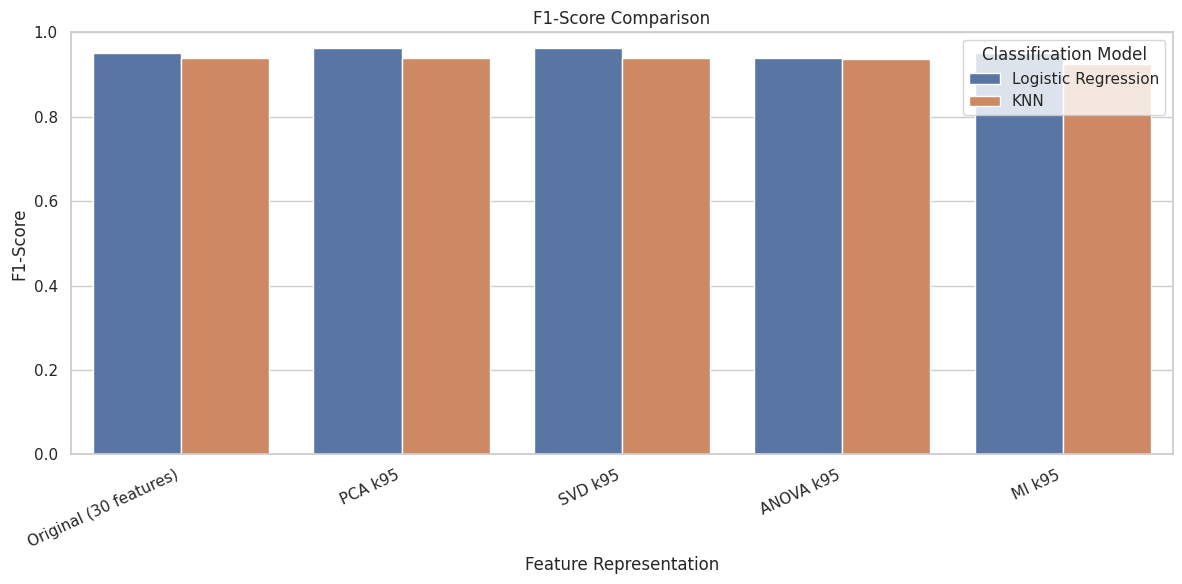

In [234]:
# Plot F1-score comparison

plt.figure(figsize=(12, 6))

sns.barplot(
    data=results_df,
    x="Representation",
    y="F1-Score",
    hue="Model"
)

plt.title("F1-Score Comparison")
plt.xlabel("Feature Representation")
plt.ylabel("F1-Score")

plt.xticks(rotation=25, ha="right")
plt.ylim(0, 1)
plt.legend(title="Classification Model")
plt.tight_layout()
plt.show()

##Does PCA/SVD reduction affect Logistic Regression and KNN in the same way?
Sol- No, PCA/SVD reduction does not necessarily affect Logistic Regression and KNN in the same way.
- Logistic Regression: PCA/SVD may maintain or improve performance by reducing redundant and correlated features. However, removing components that contain useful diagnostic information can reduce classification performance.
- K-Nearest Neighbors (KNN): PCA/SVD changes the distances between data points by projecting them into a lower-dimensional space. Removing noisy or irrelevant dimensions may improve KNN, but discarding useful dimensions may reduce its ability to identify the correct neighbors.
- PCA vs. SVD: When applied to the same standardized training data, PCA and SVD produce equivalent reduced subspaces (up to numerical precision and component sign). Therefore, their effects on both classifiers should generally be similar when the same number of components is retained.


##15: Numerical Validation and Debugging

In [235]:
import numpy as np
import pandas as pd

print("DATASET VALIDATION:- ")

print("Training shape:", X_train_scaled.shape)
print("Testing shape :", X_test_scaled.shape)

print("\nNumber of features:", X_train_scaled.shape[1])
print("Training samples :", X_train_scaled.shape[0])
print("Testing samples  :", X_test_scaled.shape[0])

print("\nMissing values in training data:",
      np.isnan(X_train_scaled).sum())
print("Missing values in testing data:",
      np.isnan(X_test_scaled).sum())

print("\nCALING VALIDATION:-  ")

print("Maximum absolute training mean:",
      np.abs(X_train_scaled.mean(axis=0)).max())

print("Maximum difference from unit training variance:",
      np.abs(X_train_scaled.var(axis=0, ddof=0) - 1).max())

DATASET VALIDATION:- 
Training shape: (455, 30)
Testing shape : (114, 30)

Number of features: 30
Training samples : 455
Testing samples  : 114

Missing values in training data: 0
Missing values in testing data: 0

CALING VALIDATION:-  
Maximum absolute training mean: 7.242070191401021e-16
Maximum difference from unit training variance: 3.3306690738754696e-16


In [236]:
#Validate Manual PCA calculations


print(" PCA VALIDATION:-")

# Reconstruct the covariance matrix from standardized training data
n_train = X_train_scaled.shape[0]
C = (X_train_scaled.T @ X_train_scaled) / (n_train - 1)

# 1. Check covariance matrix symmetry
symmetry_error = np.linalg.norm(C - C.T, ord="fro")
print("Covariance symmetry error:", symmetry_error)

# 2. Check for negative eigenvalues
print("Minimum eigenvalue:", eigenvalues.min())
print("All eigenvalues non-negative:",
      np.all(eigenvalues >= -1e-10))

# 3. Check eigenvector orthogonality
identity = np.eye(eigenvectors.shape[1])
orthogonality_error = np.linalg.norm(
    eigenvectors.T @ eigenvectors - identity,
    ord="fro"
)
print("Eigenvector orthogonality error:", orthogonality_error)

# 4. Check eigenvalue decomposition: C V = V Lambda
eigen_decomposition_error = np.linalg.norm(
    C @ eigenvectors -
    eigenvectors * eigenvalues[np.newaxis, :],
    ord="fro"
)
print("Eigenvalue decomposition error:",
      eigen_decomposition_error)

# 5. Check descending eigenvalue order
print("Eigenvalues sorted descending:",
      np.all(np.diff(eigenvalues) <= 1e-10))

# 6. Check explained variance ratios
explained_variance_ratio = eigenvalues / eigenvalues.sum()
print("Sum of explained variance ratios:",
      explained_variance_ratio.sum())

 PCA VALIDATION:-
Covariance symmetry error: 0.0
Minimum eigenvalue: 0.00012406429124630868
All eigenvalues non-negative: True
Eigenvector orthogonality error: 5.612102430515123e-15
Eigenvalue decomposition error: 1.039158569440239e-14
Eigenvalues sorted descending: True
Sum of explained variance ratios: 0.9999999999999999


In [237]:
# Validate the PCA explained varience
print("PCA VARIANCE VALIDATION:-")

cumulative_variance = np.cumsum(explained_variance_ratio)

print("k95:", k95)
print("Variance retained by k95:",
      cumulative_variance[k95 - 1])

print("At least 95% variance retained:",
      cumulative_variance[k95 - 1] >= 0.95)

# Verify that k95 is the smallest number of components
# that retains at least 95% of the variance.
previous_variance = (
    cumulative_variance[k95 - 2] if k95 > 1 else 0
)

print("Previous component count retained less than 95%:",
      previous_variance < 0.95)

PCA VARIANCE VALIDATION:-
k95: 10
Variance retained by k95: 0.9520691014391004
At least 95% variance retained: True
Previous component count retained less than 95%: True


In [238]:
# Validate SVD calculations
print("SVD VALIDATION :-")

# 1. Check reconstruction
Sigma = np.diag(S)
Z_reconstructed_svd = U @ Sigma @ Vt

svd_reconstruction_error = np.linalg.norm(
    X_train_scaled - Z_reconstructed_svd,
    ord="fro"
)

print("SVD reconstruction error:",
      svd_reconstruction_error)

# 2. Check singular values are sorted descending
print("Singular values sorted descending:",
      np.all(np.diff(S) <= 1e-10))

# 3. Check U orthogonality
u_orthogonality_error = np.linalg.norm(
    U.T @ U - np.eye(U.shape[1]),
    ord="fro"
)

print("U orthogonality error:",
      u_orthogonality_error)

# 4. Check V orthogonality
V_svd = Vt.T

v_orthogonality_error = np.linalg.norm(
    V_svd.T @ V_svd - np.eye(V_svd.shape[1]),
    ord="fro"
)

print("V orthogonality error:",
      v_orthogonality_error)

# 5. Compare PCA eigenvalues with SVD-derived eigenvalues
svd_eigenvalues = (S ** 2) / (n_train - 1)

eigenvalue_difference = np.max(
    np.abs(eigenvalues - svd_eigenvalues)
)

print("Maximum PCA-SVD eigenvalue difference:",
      eigenvalue_difference)

SVD VALIDATION :-
SVD reconstruction error: 1.726799667967889e-13
Singular values sorted descending: True
U orthogonality error: 6.9849303218503494e-15
V orthogonality error: 7.810307785549551e-15
Maximum PCA-SVD eigenvalue difference: 1.4210854715202004e-14


In [239]:
# Validate PCA and SVD reduced representation
print(" PCA-SVD COMPARISON:-")

V_pca_k95 = eigenvectors[:, :k95]
V_svd_k95 = Vt[:k95, :].T

# Projection matrices for the two reduced subspaces
P_pca = V_pca_k95 @ V_pca_k95.T
P_svd = V_svd_k95 @ V_svd_k95.T

subspace_difference = np.linalg.norm(
    P_pca - P_svd,
    ord="fro"
)

print("PCA reduced shape:", X_train_pca_k95.shape)
print("SVD reduced shape:", X_train_svd_k95.shape)

print("PCA-SVD subspace difference:",
      subspace_difference)

print("Reduced dimensions match:",
      X_train_pca_k95.shape[1] ==
      X_train_svd_k95.shape[1] == k95)

 PCA-SVD COMPARISON:-
PCA reduced shape: (455, 10)
SVD reduced shape: (455, 10)
PCA-SVD subspace difference: 1.3979542659476281e-14
Reduced dimensions match: True


In [240]:
# VAlidate reconstruction error

print("RECONSTRUCTION VALIDATION :-")
print("\n")
# Full PCA reconstruction
Z_reconstructed_pca = (
    X_train_scaled @ eigenvectors @ eigenvectors.T
)

pca_reconstruction_error = np.linalg.norm(
    X_train_scaled - Z_reconstructed_pca,
    ord="fro"
)

# Mean squared reconstruction error
pca_reconstruction_mse = np.mean(
    (X_train_scaled - Z_reconstructed_pca) ** 2
)

print("Full PCA reconstruction error:",
      pca_reconstruction_error)

print("Full PCA reconstruction MSE:",
      pca_reconstruction_mse)

# Reduced PCA reconstruction using k95 components
Z_pca_k95 = X_train_scaled @ eigenvectors[:, :k95]

Z_reconstructed_k95 = (
    Z_pca_k95 @ eigenvectors[:, :k95].T
)

reduced_pca_mse = np.mean(
    (X_train_scaled - Z_reconstructed_k95) ** 2
)

print("PCA k95 reconstruction MSE:",
      reduced_pca_mse)

print("Full PCA reconstruction is more accurate:",
      pca_reconstruction_mse <= reduced_pca_mse + 1e-10)

RECONSTRUCTION VALIDATION :-


Full PCA reconstruction error: 1.0343559865042547e-13
Full PCA reconstruction MSE: 7.83803887778161e-31
PCA k95 reconstruction MSE: 0.047930898560899673
Full PCA reconstruction is more accurate: True


In [241]:
# Final validation summary
validation_results = pd.DataFrame({
    "Validation Check": [
        "Training data has 30 features",
        "Testing data has 30 features",
        "No NaN in training data",
        "No NaN in testing data",
        "Training features standardized",
        "Covariance matrix symmetric",
        "Eigenvectors orthogonal",
        "PCA eigenvalues sorted",
        "Explained variance sums to 1",
        "k95 retains at least 95% variance",
        "SVD reconstruction accurate",
        "SVD singular values sorted",
        "PCA and SVD eigenvalues agree",
        "PCA and SVD reduced dimensions match",
        "Full PCA reconstruction accurate"
    ],
    "Passed": [
        X_train_scaled.shape[1] == 30,
        X_test_scaled.shape[1] == 30,
        not np.isnan(X_train_scaled).any(),
        not np.isnan(X_test_scaled).any(),
        np.allclose(X_train_scaled.mean(axis=0), 0, atol=1e-8)
        and np.allclose(X_train_scaled.var(axis=0), 1, atol=1e-8),
        symmetry_error < 1e-8,
        orthogonality_error < 1e-8,
        np.all(np.diff(eigenvalues) <= 1e-10),
        np.isclose(explained_variance_ratio.sum(), 1, atol=1e-8),
        cumulative_variance[k95 - 1] >= 0.95,
        svd_reconstruction_error < 1e-6,
        np.all(np.diff(S) <= 1e-10),
        eigenvalue_difference < 1e-6,
        X_train_pca_k95.shape[1] == X_train_svd_k95.shape[1] == k95,
        pca_reconstruction_mse < 1e-10
    ]
})

display(validation_results)

print("\nPassed:",
      validation_results["Passed"].sum(),
      "out of",
      len(validation_results))

if validation_results["Passed"].all():
    print("All validation checks passed!")
else:
    print("Some checks failed. Review the failed checks.")
    display(validation_results[~validation_results["Passed"]])

,Validation Check,Passed
0,Training data has 30 features,True
1,Testing data has 30 features,True
2,No NaN in training data,True
3,No NaN in testing data,True
4,Training features standardized,True
5,Covariance matrix symmetric,True
6,Eigenvectors orthogonal,True
7,PCA eigenvalues sorted,True
8,Explained variance sums to 1,True
9,k95 retains at least 95% variance,True



Passed: 15 out of 15
All validation checks passed!


##16: Final Experimental Summary


In [242]:


master_rows = []

representations_info = [
    {
        "Representation": "Original",
        "Task14_Name": "Original (30 features)",
        "Dimensions": 30,
        "Type": "Original",
        "Variance Retained": "100%"
    },
    {
        "Representation": "PCA",
        "Task14_Name": "PCA k95",
        "Dimensions": k95,
        "Type": "Extraction",
        "Variance Retained": f"{np.sum(explained_variance_ratio[:k95]) * 100:.2f}%"
    },
    {
        "Representation": "SVD",
        "Task14_Name": "SVD k95",
        "Dimensions": k95,
        "Type": "Extraction",
        "Variance Retained": f"{np.sum(S[:k95]**2) / np.sum(S**2) * 100:.2f}%"
    },
    {
        "Representation": "ANOVA",
        "Task14_Name": "ANOVA k95",
        "Dimensions": k95,
        "Type": "Selection",
        "Variance Retained": "N/A"
    },
    {
        "Representation": "Mutual Information",
        "Task14_Name": "MI k95",
        "Dimensions": k95,
        "Type": "Selection",
        "Variance Retained": "N/A"
    }
]

for item in representations_info:

    task14_name = item["Task14_Name"]

    lr_rows = results_df[
        (results_df["Representation"] == task14_name) &
        (results_df["Model"] == "Logistic Regression")
    ]

    knn_rows = results_df[
        (results_df["Representation"] == task14_name) &
        (results_df["Model"] == "KNN")
    ]

    # Raise an error if the expected results are missing
    if lr_rows.empty or knn_rows.empty:
        print(f"Warning: Missing Task 14 results for {task14_name}")
        lr_f1 = np.nan
        knn_f1 = np.nan
    else:
        lr_f1 = lr_rows["F1-Score"].iloc[0]
        knn_f1 = knn_rows["F1-Score"].iloc[0]

    master_rows.append({
        "Representation": item["Representation"],
        "Dimensions": item["Dimensions"],
        "Type": item["Type"],
        "Variance Retained": item["Variance Retained"],
        "LR F1": lr_f1,
        "KNN F1": knn_f1
    })

master_table = pd.DataFrame(master_rows)

display(master_table.round(4))

,Representation,Dimensions,Type,Variance Retained,LR F1,KNN F1
0,Original,30,Original,100%,0.9512,0.9383
1,PCA,10,Extraction,95.21%,0.9630,0.9383
2,SVD,10,Extraction,95.21%,0.9630,0.9383
3,ANOVA,10,Selection,N/A,0.9383,0.9367
4,Mutual Information,10,Selection,N/A,0.9512,0.9250


## Final Scientific Interpretation



- **Redundancy & PCA:** The original features showed substantial redundancy, with **21 pairs having |r| ≥ 0.90**. The eigenvalue spectrum showed that **7, 10, and 17 components** retained **90%, 95%, and 99%** of the variance, respectively.

- **PCA & reconstruction:** The PC1–PC2 plot showed **partial separation** between the diagnosis classes, with noticeable overlap. Reconstruction MSE **decreased as more components were retained**, reaching zero with all 30 components.

- **PCA vs SVD:** The numerical relationship between PCA and SVD was **successfully verified**, confirming their equivalent variance representation.

- **Feature selection:** ANOVA selected features including **concave_points_worst, perimeter_worst, radius_worst, and concave_points_mean**, while Mutual Information selected **radius_worst, perimeter_worst, area_worst, and concave_points_mean**, among others. Feature selection preserves the original feature meanings, making it more interpretable than PCA/SVD.

- **Model performance & trade-off:** **PCA/SVD provided the better compact representation for Logistic Regression** (F1 = **0.9630**), while KNN remained unchanged (F1 = **0.9383**). However, compression can lose **lower-variance information, subtle patterns, and direct feature interpretability**.